# ECG-FM Clinical Overlay + XAI (prototype)

1. ECG Data Preparation	*
2. XAI Method Development	*
3. XAI Visualization	*
4. Clinical Landmarks	*
5. STEMI-Specific Explanation	- wait for model integration


In [1]:
%pip -q install 'huggingface_hub>=0.24' 'wfdb>=4.1' scipy numpy pandas matplotlib 'captum>=0.7'
import os, subprocess
if not os.path.exists('/content/fairseq-signals/.git'):
    subprocess.run(['git','clone','--depth','1','https://github.com/Jwoo5/fairseq-signals.git','/content/fairseq-signals'], check=True)
%pip -q install -e /content/fairseq-signals

  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Installing backend dependencies ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for fairseq_signals (pyproject.toml) ... done


In [2]:
from pathlib import Path
import numpy as np
import torch
import matplotlib.pyplot as plt
from scipy.signal import find_peaks, resample_poly, butter, sosfiltfilt
from fractions import Fraction

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
FS = 500
DURATION_SECONDS = 5
LEADS = ['I','II','III','aVR','aVL','aVF','V1','V2','V3','V4','V5','V6']
RUN_FM_XAI = True
RUN_DEEPLIFT = False
IG_STEPS = 32
USE_MANUAL_LANDMARKS = False
print('Device:', DEVICE)

Device: cuda


In [3]:
import wfdb
from urllib.request import urlretrieve
sample_dir = Path('/content/ptbxl_ecg_demo')
sample_dir.mkdir(exist_ok=True)
base_url = 'https://physionet.org/files/ptb-xl/1.0.3/records500/00000/00001_hr'
for ext in ('.hea','.dat'):
    p = sample_dir / ('00001_hr'+ext)
    if not p.exists():
        urlretrieve(base_url+ext,p)

rec = wfdb.rdrecord(str(sample_dir/'00001_hr'))
raw = np.asarray(rec.p_signal,dtype=np.float32).T
raw_names = [x.replace('AVR','aVR').replace('AVL','aVL').replace('AVF','aVF') for x in rec.sig_name]
assert set(LEADS) <= set(raw_names)
raw = raw[[raw_names.index(s) for s in LEADS]]
raw_fs = float(rec.fs)


if raw_fs != FS:
    frac=Fraction(FS/raw_fs).limit_denominator(1000)
    raw=resample_poly(raw,frac.numerator,frac.denominator,axis=1).astype(np.float32)

start_sample = 0
end_sample = start_sample + int(FS*DURATION_SECONDS)
assert raw.shape[1] >= end_sample, 'Record shorter than requested crop'
display_ecg = raw[:,start_sample:end_sample].copy()
x_norm=display_ecg.copy()



for j in range(12):
    mu,sd=float(x_norm[j].mean()),float(x_norm[j].std())
    x_norm[j]= (x_norm[j]-mu)/sd if sd > 1e-8 else 0
source=torch.from_numpy(x_norm).unsqueeze(0).to(DEVICE)
assert source.shape==(1,12,int(FS*DURATION_SECONDS))


print('display:',display_ecg.shape,'model:',tuple(source.shape),'start:',start_sample/FS,'s')

/usr/local/lib/python3.12/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


display: (12, 2500) model: (1, 12, 2500) start: 0.0 s


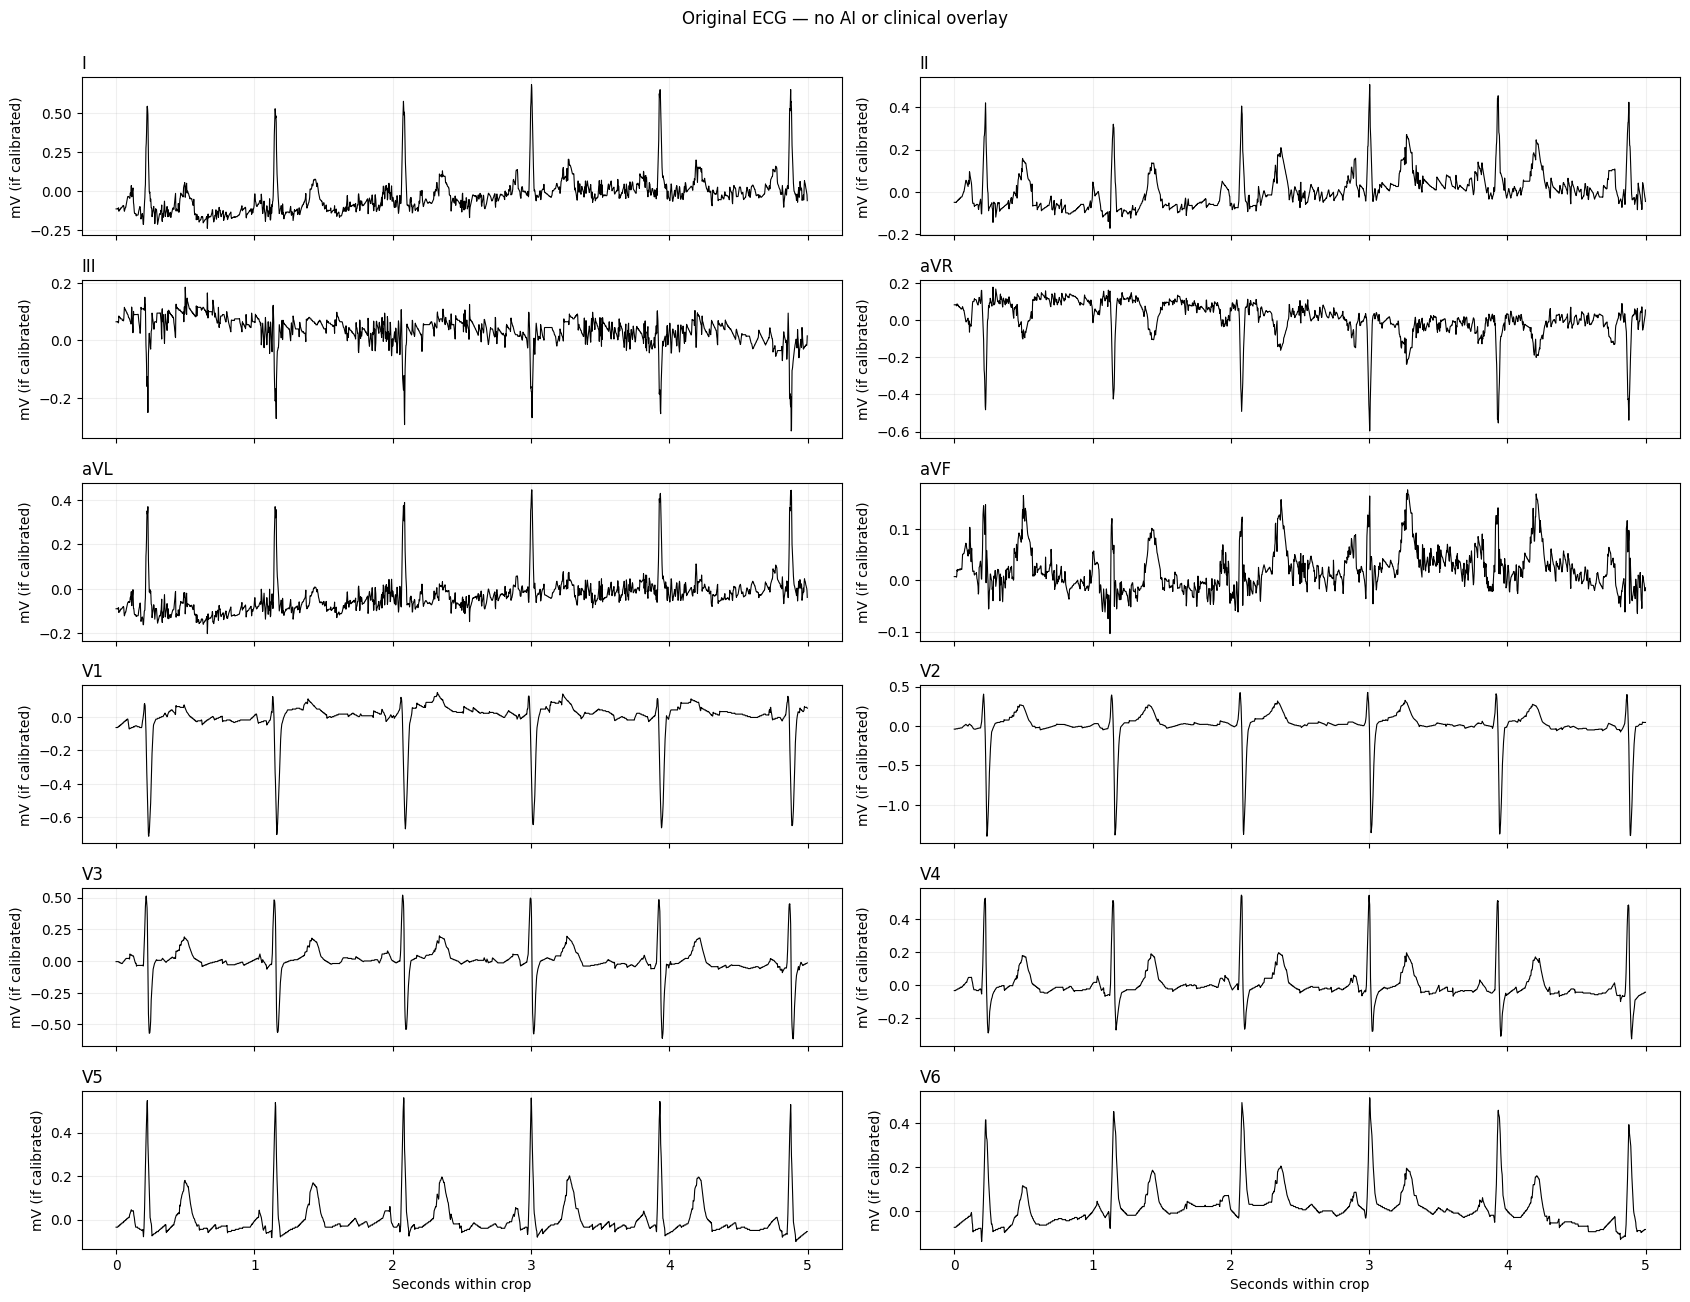

In [4]:
def plot_ecg(ecg, overlays=None, title='12-lead ECG', show_legend=True):
    overlays=overlays or []
    assert ecg.shape[0]==12

    t=np.arange(ecg.shape[1])/FS
    fig,axes=plt.subplots(6,2,figsize=(17,13),sharex=True)

    for i,(lead,ax) in enumerate(zip(LEADS,axes.ravel())):
        ax.plot(t,ecg[i],color='black',lw=.8,zorder=3)
        for r in overlays:
            if r['lead']==lead:
                ax.axvspan(r['start_s'],r['end_s'],color=r.get('color','tab:red'),alpha=.28,label=r.get('label','overlay'),zorder=1)
        ax.set_title(lead,loc='left'); ax.grid(alpha=.2)
        ax.set_ylabel('mV (if calibrated)')

    for ax in axes[-1]: ax.set_xlabel('Seconds within crop')

    if show_legend:
        handles,labels=axes[0,0].get_legend_handles_labels()
        if handles: fig.legend(handles,labels,loc='upper right')
    fig.suptitle(title,y=.998)
    fig.tight_layout()
    return fig,axes

plot_ecg(display_ecg,title='Original ECG — no AI or clinical overlay');

## Clinical reference (not AI attribution)

**Important:** Automatic landmark estimation here is a **rough signal-processing prototype**, not validated QRS-offset or J-point annotation. It must **not** be interpreted as a STEMI detection rule. For actual comparison with XAI, replace estimates with physician-reviewed intervals and/or independently validated delineation. Use `MANUAL_INTERVALS` for reviewed annotations.

Tentative R-peaks (sec): [0.224 1.15  2.078 3.002 3.932]


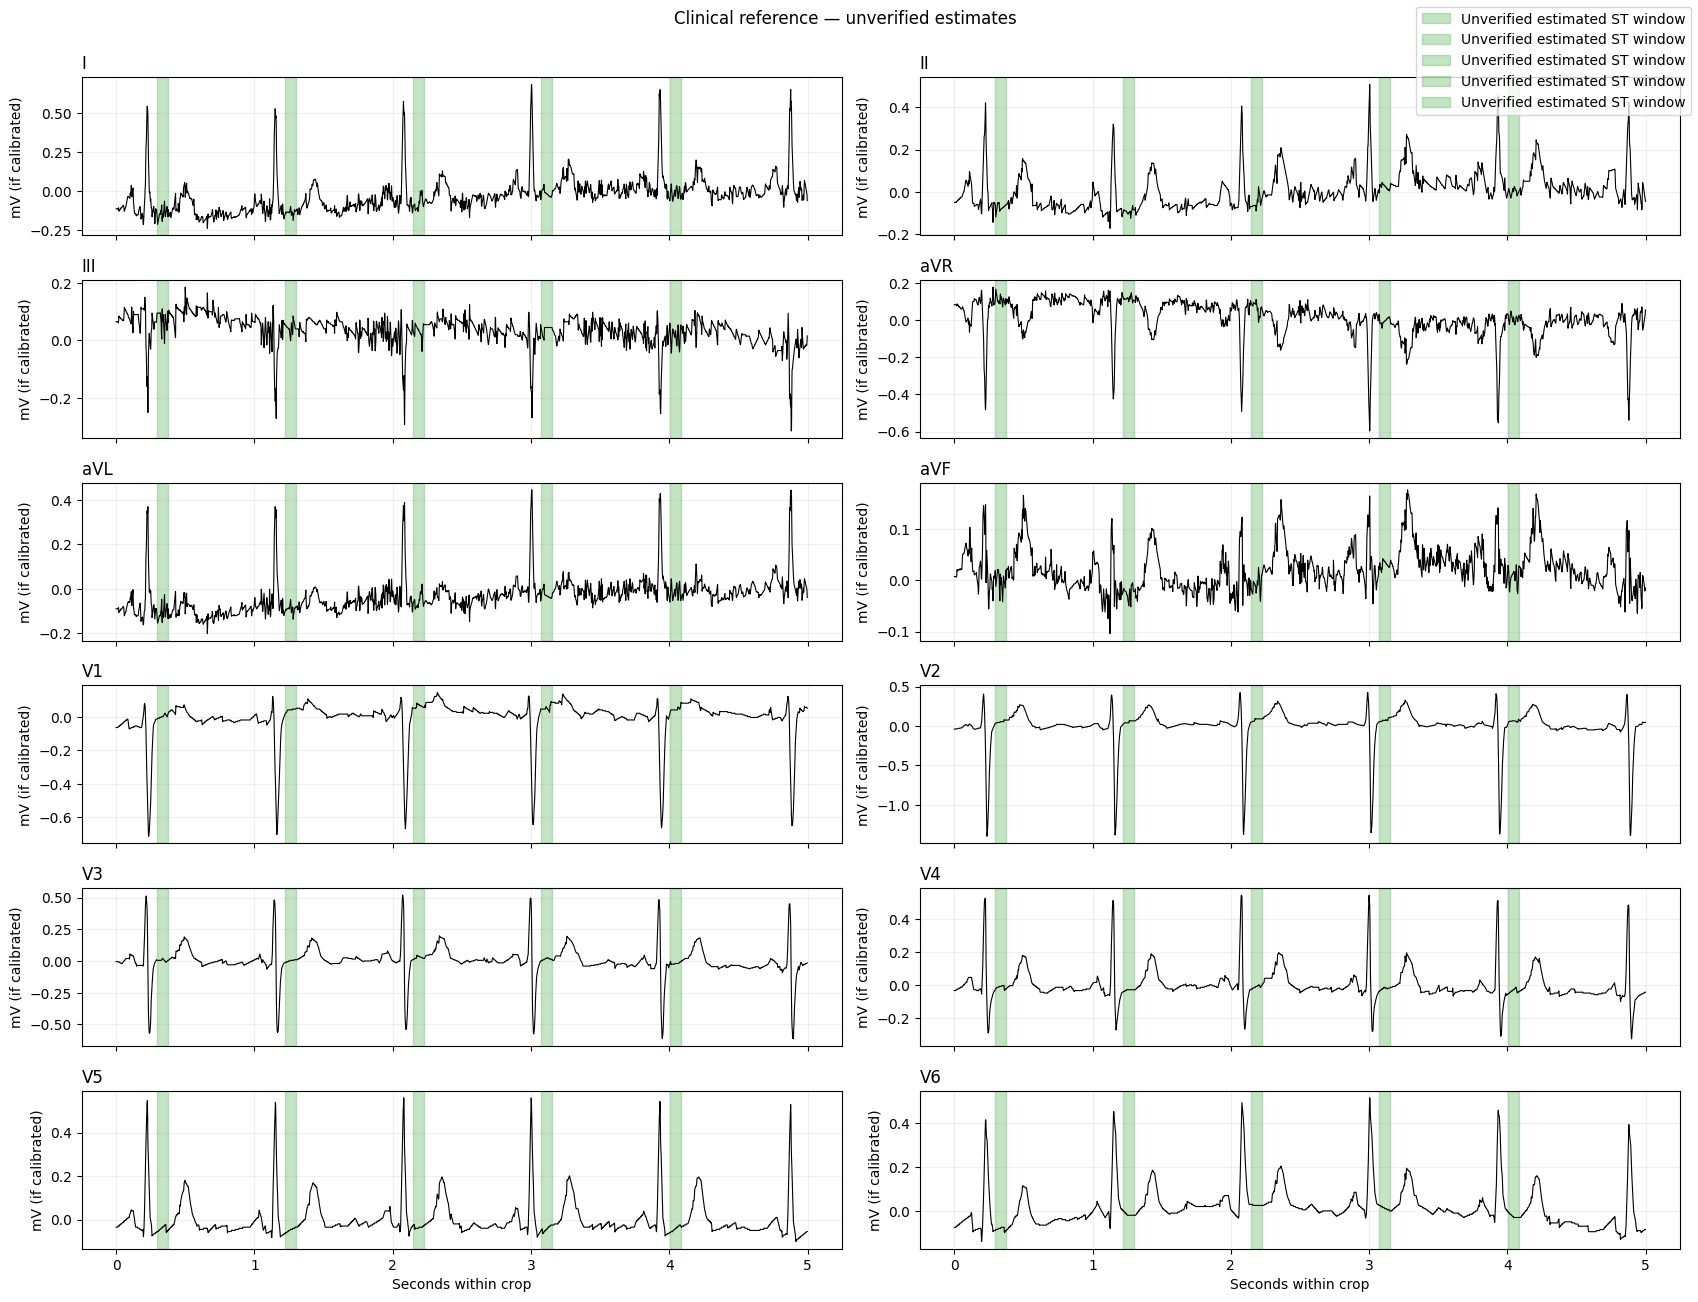

In [5]:
lead_ii=display_ecg[LEADS.index('II')]
sos=butter(2,[5,25],btype='bandpass',fs=FS,output='sos')
filtered=sosfiltfilt(sos,lead_ii)
peaks,_=find_peaks(np.abs(filtered),distance=int(.32*FS),prominence=max(np.std(filtered)*1.3,1e-4))


peaks=peaks[(peaks > int(.12*FS)) & (peaks < display_ecg.shape[1]-int(.25*FS))]
print('Tentative R-peaks (sec):',np.round(peaks/FS,3))

AUTO_INTERVALS=[]
for r in peaks:
    st_start=(r+int(.07*FS))/FS
    st_end=(r+int(.15*FS))/FS
    for lead in LEADS:
        AUTO_INTERVALS.append({'lead':lead,'start_s':st_start,'end_s':st_end,'color':'tab:green','label':'Unverified estimated ST window'})

MANUAL_INTERVALS=[]  # e.g. [{'lead':'II','start_s':1.20,'end_s':1.28,'color':'tab:green','label':'Physician ST reference'}]
clinical_intervals=MANUAL_INTERVALS if USE_MANUAL_LANDMARKS else AUTO_INTERVALS
plot_ecg(display_ecg,clinical_intervals,title='Clinical reference — unverified estimates' if not USE_MANUAL_LANDMARKS else 'Physician-reviewed clinical reference');

PASS: synthetic attribution maps to Lead III at t=2.0 s


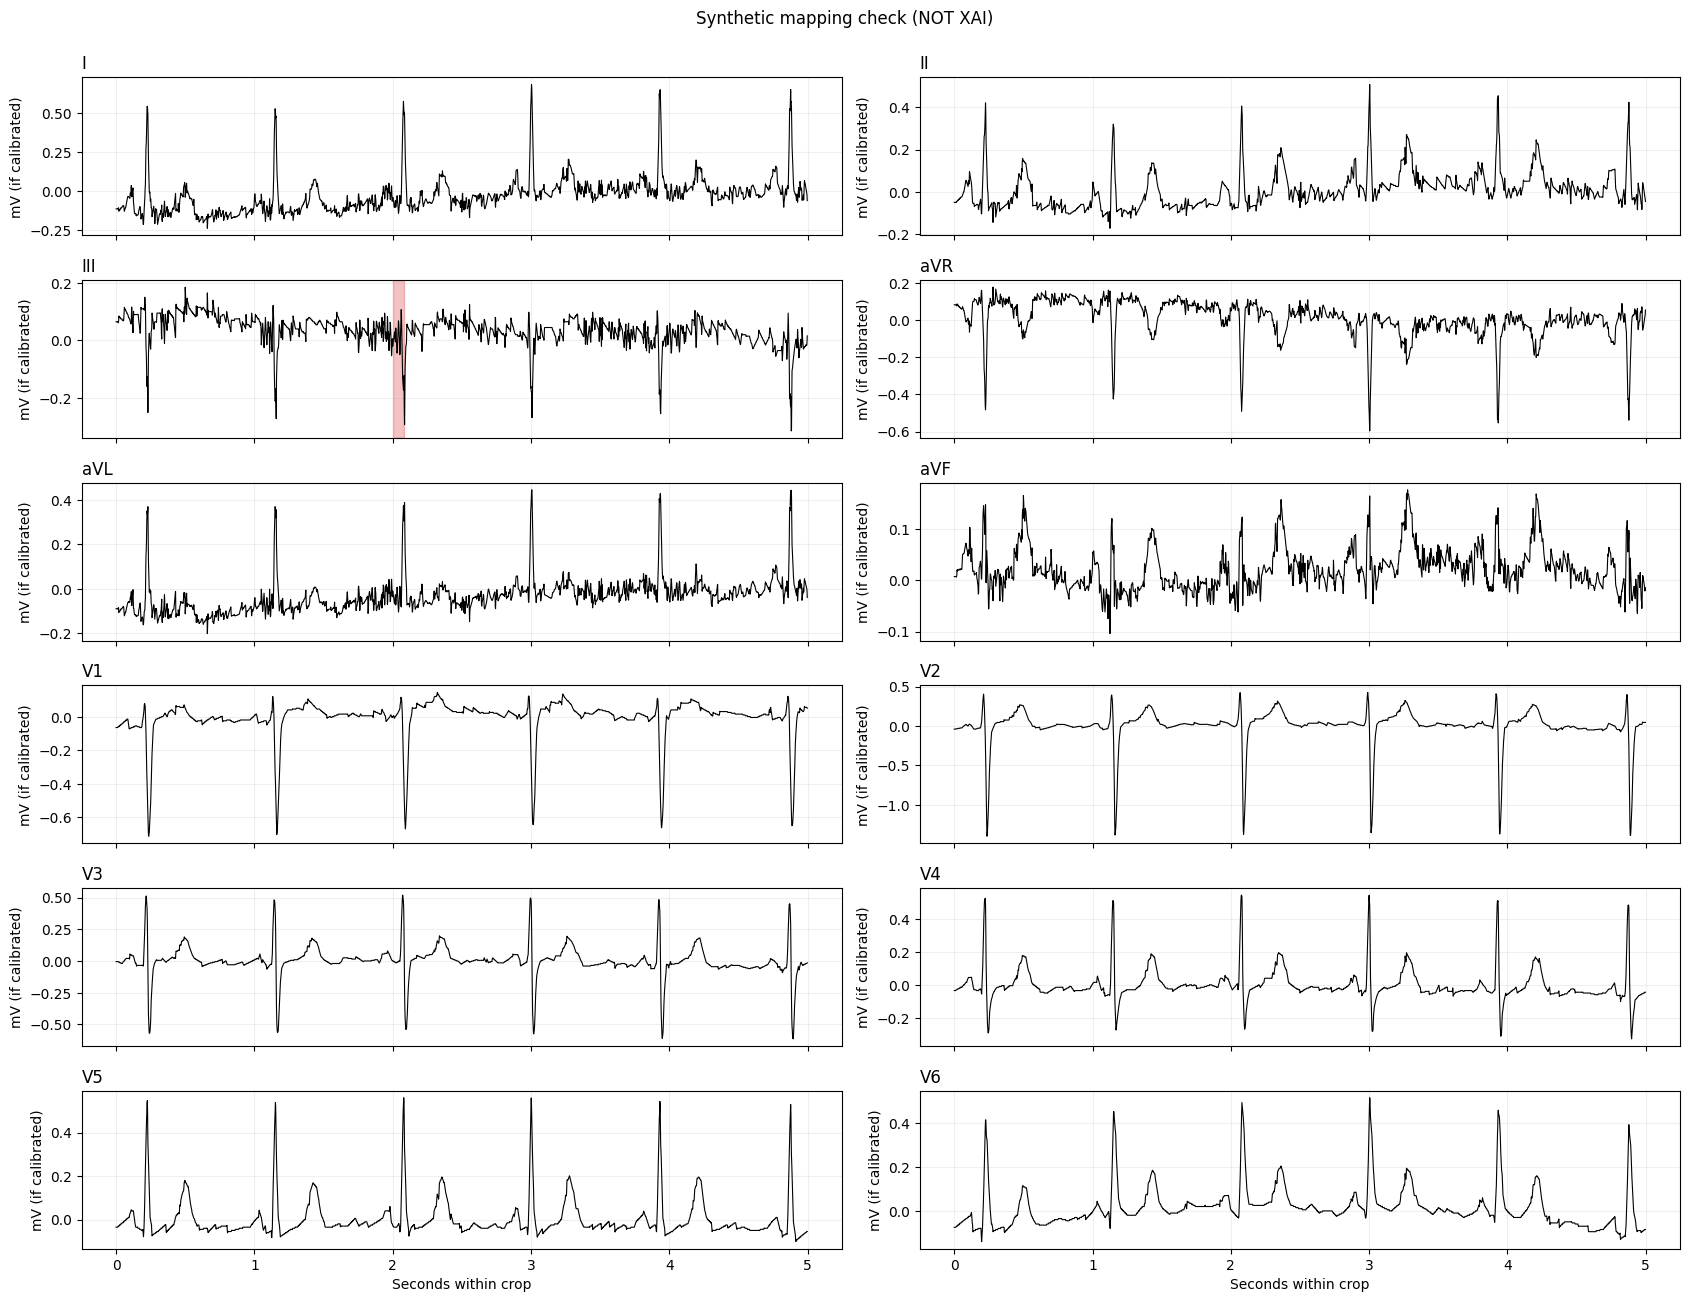

In [6]:
synthetic=np.zeros_like(display_ecg)
row=LEADS.index('III'); sample=int(2.0*FS)
synthetic[row,sample:sample+int(.08*FS)]=1.0
assert np.argmax(synthetic.max(axis=1))==row
assert np.argmax(synthetic[row])==sample

def attribution_regions(attr, top_percentile=99.0, max_regions_per_lead=12, positive_only=True):
    values=np.maximum(attr,0) if positive_only else np.maximum(-attr,0)
    if not np.any(values>0): return []
    threshold=np.percentile(values[values>0],top_percentile)
    mask=values>=threshold
    result=[]
    for i,lead in enumerate(LEADS):
        starts=np.flatnonzero(np.diff(np.r_[False,mask[i],False].astype(int))==1)
        ends=np.flatnonzero(np.diff(np.r_[False,mask[i],False].astype(int))==-1)
        intervals=sorted(zip(starts,ends),key=lambda se:float(values[i,se[0]:se[1]].max()),reverse=True)
        for a,b in sorted(intervals[:max_regions_per_lead]):
            result.append({'lead':lead,'start_s':a/FS,'end_s':b/FS,'color':'tab:red' if positive_only else 'tab:blue','label':'positive FM feature attribution' if positive_only else 'negative FM feature attribution'})
    return result

regions=attribution_regions(synthetic,top_percentile=95)
assert len(regions)>0 and all(r['lead']=='III' for r in regions)
assert any(r['start_s']<=2.0<r['end_s'] for r in regions)
print('PASS: synthetic attribution maps to Lead III at t=2.0 s')
plot_ecg(display_ecg,regions,title='Synthetic mapping check (NOT XAI)');

## Pretrained ECG-FM feature attribution

This pretrained checkpoint produces representations, **not a STEMI logit**. The temporary scalar below measures feature magnitude. Attribution answers *which inputs influence this artificial feature score*, **not** *why STEMI was predicted*. When the trained STEMI classifier becomes available, replace the target forward function, checkpoint, and preprocessing with the team's verified inference code.

In [7]:
%cd /content

!git clone https://github.com/Jwoo5/fairseq-signals.git

%cd /content/fairseq-signals

%pip install -e .

/content
fatal: destination path 'fairseq-signals' already exists and is not an empty directory.
/content/fairseq-signals
Obtaining file:///content/fairseq-signals
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Installing backend dependencies ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for fairseq_signals (pyproject.toml) ... done
  Created wheel for fairseq_signals: filename=fairseq_signals-1.0.0a0+f8f0ff1-0.editable-cp312-cp312-linux_x86_64.whl size=6635 sha256=a49070a1f8deed865a9ad0e6cd5def3f3124cad0011dda87672814fe6aaf0fc0
  Stored in directory: /tmp/pip-ephem-wheel-cache-om06tf7n/wheels/9a/e6/fd/7847bdc7c0122549e05ab9a85afaf7479add63bf3bee83f1ae
Successfully built fairseq_signals
  Attempting uninstall: fairseq_signals
    Found existing installation: fairseq_signals 1.0.0a0+f8f0ff1
    Uninstalling fairseq_signals-1.0.0a0+f8f0ff1:
   

In [8]:
%pip install -q --force-reinstall --no-deps "transformers==4.44.2"

In [9]:
%pip install --only-binary=:all: --force-reinstall --no-deps "tokenizers==0.19.1"

  Using cached tokenizers-0.19.1-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (6.7 kB)
Using cached tokenizers-0.19.1-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (3.6 MB)
  Attempting uninstall: tokenizers
    Found existing installation: tokenizers 0.19.1
    Uninstalling tokenizers-0.19.1:
      Successfully uninstalled tokenizers-0.19.1


In [10]:
%pip uninstall -y huggingface-hub hf-xet

%pip install --no-cache-dir --force-reinstall \
    "huggingface-hub==0.25.2" \
    "transformers==4.44.2" \
    "tokenizers==0.19.1"

Found existing installation: huggingface_hub 0.36.2
Uninstalling huggingface_hub-0.36.2:
  Successfully uninstalled huggingface_hub-0.36.2
Found existing installation: hf-xet 1.5.1
Uninstalling hf-xet-1.5.1:
  Successfully uninstalled hf-xet-1.5.1
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 91.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.4/57.4 kB 188.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.6/40.6 kB 174.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.4/46.4 kB 173.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 436.6/436.6 kB 61.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 80.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 241.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 221.7/221.7 kB 256.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 207.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [11]:
import transformers
import tokenizers
from transformers import DataCollatorForWholeWordMask

print("Transformers:", transformers.__version__)
print("Tokenizers:", tokenizers.__version__)
print("Transformers import OK!")

Transformers: 4.44.2
Tokenizers: 0.19.1
Transformers import OK!


In [12]:
from pathlib import Path

root = Path("/content/fairseq-signals")

print("Repository exists:", root.exists())

print("\nRegistry files:")
for p in root.rglob("*registry*.py"):
    print(p)

print("\nFiles containing setup_registry:")
for p in root.rglob("*.py"):
    try:
        if "setup_registry" in p.read_text():
            print(p)
    except (UnicodeDecodeError, OSError):
        pass

Repository exists: True

Registry files:
/content/fairseq-signals/fairseq_signals/utils/registry.py

Files containing setup_registry:
/content/fairseq-signals/fairseq_signals/optim/__init__.py
/content/fairseq-signals/fairseq_signals/criterions/__init__.py
/content/fairseq-signals/fairseq_signals/utils/registry.py
/content/fairseq-signals/fairseq_signals/optim/lr_scheduler/__init__.py


In [13]:
from pathlib import Path

p = Path(
    "/content/fairseq-signals/fairseq_signals/utils/registry.py"
)

source = p.read_text()

start = source.find("def setup_registry")
end = source.find("\ndef ", start + 1)

if end == -1:
    end = start + 6000

print(source[start:end])

def setup_registry(registry_name: str, base_class = None, default = None, required = False):
    assert registry_name.startswith("--")
    registry_name = registry_name[2:].replace("-", "_")

    REGISTRY = {}
    REGISTRY_CLASS_NAMES = set()
    DATACLASS_REGISTRY = {}

    # maintain a registry of all registries
    if registry_name in REGISTRIES:
        import traceback
        print(f"DUPLICATE REGISTRY: {registry_name}")
        traceback.print_stack(limit=12)
        return # registry already exists
    REGISTRIES[registry_name] = {
        "registry" : REGISTRY,
        "default" : default,
        "dataclass_registry" : DATACLASS_REGISTRY
    }

    def build_x(cfg: Union[DictConfig, str, Namespace], *extra_args, **extra_kwargs):
        if isinstance(cfg, DictConfig):
            choice = cfg._name

            if choice and choice in DATACLASS_REGISTRY:
                from_checkpoint = extra_kwargs.get("from_checkpoint", False)
                dc = DATACLASS_REGISTRY[choice

In [14]:
from pathlib import Path

p = Path(
    "/content/fairseq-signals/fairseq_signals/"
    "utils/registry.py"
)

source = p.read_text()

start = source.find("REGISTRIES =")
print(source[start:start + 1000])

REGISTRIES = {}

def setup_registry(registry_name: str, base_class = None, default = None, required = False):
    assert registry_name.startswith("--")
    registry_name = registry_name[2:].replace("-", "_")

    REGISTRY = {}
    REGISTRY_CLASS_NAMES = set()
    DATACLASS_REGISTRY = {}

    # maintain a registry of all registries
    if registry_name in REGISTRIES:
        import traceback
        print(f"DUPLICATE REGISTRY: {registry_name}")
        traceback.print_stack(limit=12)
        return # registry already exists
    REGISTRIES[registry_name] = {
        "registry" : REGISTRY,
        "default" : default,
        "dataclass_registry" : DATACLASS_REGISTRY
    }

    def build_x(cfg: Union[DictConfig, str, Namespace], *extra_args, **extra_kwargs):
        if isinstance(cfg, DictConfig):
            choice = cfg._name

            if choice and choice in DATACLASS_REGISTRY:
                from_checkpoint = extra_kwargs.get("from_checkpoint", False)
                dc = DATACLAS

In [15]:
from pathlib import Path

root = Path("/content/fairseq-signals/fairseq_signals")

for p in root.rglob("*.py"):
    try:
        lines = p.read_text().splitlines()
        for i, line in enumerate(lines, 1):
            if "setup_registry(" in line and not line.strip().startswith("def "):
                print(f"{p.relative_to(root)}:{i}: {line.strip()}")
    except (UnicodeDecodeError, OSError):
        pass

optim/__init__.py:28: ) = registry.setup_registry("--optimizer", base_class = Optimizer, required = True)
criterions/__init__.py:18: ) = registry.setup_registry(
optim/lr_scheduler/__init__.py:20: ) = registry.setup_registry(


In [16]:
from pathlib import Path

root = Path("/content/fairseq-signals/fairseq_signals")

for relative in [
    "optim/__init__.py",
    "optim/lr_scheduler/__init__.py",
]:
    print(f"\n--- {relative} ---")
    p = root / relative
    for i, line in enumerate(p.read_text().splitlines()[:45], 1):
        print(f"{i:3}: {line}")


--- optim/__init__.py ---
  1: # Copyright (c) Facebook, Inc. and its affiliates.
  2: #
  3: # This source code is licensed under the MIT license found in the
  4: # LICENSE file in the root directory of this source tree.
  5: 
  6: import importlib
  7: import os
  8: 
  9: from fairseq_signals.utils import registry
 10: from fairseq_signals.optim.optimizer import (
 11:     Optimizer,
 12: )
 13: from fairseq_signals.optim.fp16_optimizer import FP16Optimizer, MemoryEfficientFP16Optimizer
 14: 
 15: from omegaconf import DictConfig
 16: 
 17: __all__ = [
 18:     "Optimizer",
 19:     "FP16Optimizer",
 20:     "MemoryEfficientFP16Optimizer"
 21: ]
 22: 
 23: (
 24:     _build_optimizer,
 25:     register_optimizer,
 26:     OPTIMIZER_REGISTRY,
 27:     OPTIMIZER_DATACLASS_REGISTRY
 28: ) = registry.setup_registry("--optimizer", base_class = Optimizer, required = True)
 29: 
 30: def build_optimizer(cfg: DictConfig, params, *extra_args, **extra_kwargs):
 31:     if all(isinstance(p, 

In [17]:
from pathlib import Path

p = Path(
    "/content/fairseq-signals/"
    "fairseq_signals/criterions/__init__.py"
)

for i, line in enumerate(p.read_text().splitlines()[:85], 1):
    print(f"{i:3}: {line}")

  1: # Copyright (c) Facebook, Inc. and its affiliates.
  2: #
  3: # This source code is licensed under the MIT license found in the
  4: # LICENSE file in the root directory of this source tree.
  5: 
  6: import importlib
  7: import os
  8: 
  9: from fairseq_signals.utils import registry
 10: from fairseq_signals.criterions.criterion import BaseCriterion # noqa
 11: from omegaconf import DictConfig
 12: 
 13: (
 14:     build_criterion_,
 15:     register_criterion,
 16:     CRITERION_REGISTRY,
 17:     CRITERION_DATACLASS_REGISTRY
 18: ) = registry.setup_registry(
 19:     "--criterion", base_class=BaseCriterion, default="cross_entropy"
 20: )
 21: 
 22: def build_criterion(cfg: DictConfig, task, from_checkpoint=False) -> BaseCriterion:
 23:     return build_criterion_(cfg, task, from_checkpoint=from_checkpoint)
 24: 
 25: # automatically import any Python files in the criterions/ directory
 26: for file in sorted(os.listdir(os.path.dirname(__file__))):
 27:     if file.endswith(

In [18]:
from pathlib import Path

p = Path(
    "/content/fairseq-signals/"
    "fairseq_signals/criterions/__init__.py"
)

for i, line in enumerate(p.read_text().splitlines()[:85], 1):
    print(f"{i:3}: {line}")

  1: # Copyright (c) Facebook, Inc. and its affiliates.
  2: #
  3: # This source code is licensed under the MIT license found in the
  4: # LICENSE file in the root directory of this source tree.
  5: 
  6: import importlib
  7: import os
  8: 
  9: from fairseq_signals.utils import registry
 10: from fairseq_signals.criterions.criterion import BaseCriterion # noqa
 11: from omegaconf import DictConfig
 12: 
 13: (
 14:     build_criterion_,
 15:     register_criterion,
 16:     CRITERION_REGISTRY,
 17:     CRITERION_DATACLASS_REGISTRY
 18: ) = registry.setup_registry(
 19:     "--criterion", base_class=BaseCriterion, default="cross_entropy"
 20: )
 21: 
 22: def build_criterion(cfg: DictConfig, task, from_checkpoint=False) -> BaseCriterion:
 23:     return build_criterion_(cfg, task, from_checkpoint=from_checkpoint)
 24: 
 25: # automatically import any Python files in the criterions/ directory
 26: for file in sorted(os.listdir(os.path.dirname(__file__))):
 27:     if file.endswith(

In [20]:
from pathlib import Path

p = Path("/content/fairseq-signals/fairseq_signals/utils/registry.py")

source = p.read_text()

for i, line in enumerate(source.splitlines(), 1):
    if "registry_name in REGISTRIES" in line:
        start = max(0, i - 6)
        end = min(len(source.splitlines()), i + 8)

        for j in range(start, end):
            print(f"{j+1}: {source.splitlines()[j]}")

20:     REGISTRY = {}
21:     REGISTRY_CLASS_NAMES = set()
22:     DATACLASS_REGISTRY = {}
23: 
24:     # maintain a registry of all registries
25:     if registry_name in REGISTRIES:
26:         import traceback
27:         print(f"DUPLICATE REGISTRY: {registry_name}")
28:         traceback.print_stack(limit=12)
29:         return # registry already exists
30:     REGISTRIES[registry_name] = {
31:         "registry" : REGISTRY,
32:         "default" : default,
33:         "dataclass_registry" : DATACLASS_REGISTRY


In [23]:
from pathlib import Path

p = Path("/content/fairseq-signals/fairseq_signals/utils/registry.py")
source = p.read_text()

old = '''    if registry_name in REGISTRIES:
        return # registry already exists'''

new = '''    if registry_name in REGISTRIES:
        import traceback
        print(f"DUPLICATE REGISTRY: {registry_name}")
        traceback.print_stack(limit=12)
        return # registry already exists'''

if new in source:
    print("Registry already patched. Skipping.")
elif old in source:
    p.write_text(source.replace(old, new, 1))
    print("Registry patch applied.")
else:
    raise RuntimeError(
        "Unknown registry.py structure. No changes made."
    )

Registry already patched. Skipping.


In [25]:
from fairseq_signals.models import build_model_from_checkpoint
print("ECG-FM import successful!")

ECG-FM import successful!


In [26]:
model=None
if RUN_FM_XAI:
    from huggingface_hub import hf_hub_download
    from fairseq_signals.models import build_model_from_checkpoint
    ckpt=hf_hub_download(repo_id='wanglab/ecg-fm',filename='mimic_iv_ecg_physionet_pretrained.pt')
    model=build_model_from_checkpoint(checkpoint_path=str(ckpt)).to(DEVICE).eval()
    print('Loaded model:',type(model).__name__)
else:
    print('Skip model branch; clinical / mapping visualization remains usable.')

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_token.py:90: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


mimic_iv_ecg_physionet_pretrained.pt:   0%|          | 0.00/1.09G [00:00<?, ?B/s]

Loaded model: Wav2Vec2CMSCModel


In [27]:
import numpy as np
import torch

for name, value in list(globals().items()):
    if isinstance(value, (np.ndarray, torch.Tensor)):
        if value.ndim in (2, 3):
            print(name, value.shape, type(value).__name__)

raw (12, 5000) ndarray
display_ecg (12, 2500) ndarray
x_norm (12, 2500) ndarray
sos (2, 6) ndarray
synthetic (12, 2500) ndarray


In [28]:
import torch

ecg_tensor = torch.as_tensor(
    x_norm,
    dtype=torch.float32,
    device=DEVICE
).unsqueeze(0)

print("ECG Tensor:", ecg_tensor.shape)
print("Device:", ecg_tensor.device)

ECG Tensor: torch.Size([1, 12, 2500])
Device: cuda:0


In [36]:
import torch
import torch.nn as nn

class PretrainedFeatureTarget(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, x):
        output = self.model(source=x)

        if isinstance(output, dict):
            if "features" in output:
                features = output["features"]
            elif "encoder_out" in output:
                features = output["encoder_out"]
            elif "x" in output:
                features = output["x"]
            else:
                raise KeyError(
                    f"Available output keys: {list(output.keys())}"
                )

        elif isinstance(output, (tuple, list)):
            features = output[0]
        else:
            features = output

        if not isinstance(features, torch.Tensor):
            raise TypeError(
                f"Expected Tensor, got {type(features)}"
            )

        return features.abs().mean(
            dim=tuple(range(1, features.ndim))
        )

In [32]:
%pip install -q captum

In [34]:
import torch
from captum.attr import IntegratedGradients

print("Captum IntegratedGradients ready!")

Captum IntegratedGradients ready!


In [37]:
ig_attr = None

if RUN_FM_XAI:
    target = PretrainedFeatureTarget(model).eval()

    baseline = torch.zeros_like(ecg_tensor)
    ig = IntegratedGradients(target)

    ig_attr, convergence_delta = ig.attribute(
        ecg_tensor,
        baselines=baseline,
        n_steps=IG_STEPS,
        internal_batch_size=1,
        return_convergence_delta=True
    )

    assert ig_attr.shape == ecg_tensor.shape

    print("IG shape:", tuple(ig_attr.shape))
    print("Convergence delta:", convergence_delta.detach().cpu().numpy())

IG shape: (1, 12, 2500)
Convergence delta: [0.30939633]


In [39]:
IG_STEPS = 32

baseline = torch.zeros_like(ecg_tensor)
ig = IntegratedGradients(target)

ig_attr, convergence_delta = ig.attribute(
    ecg_tensor,
    baselines=baseline,
    n_steps=IG_STEPS,
    method="gausslegendre",
    internal_batch_size=1,
    return_convergence_delta=True
)

with torch.no_grad():
    score_input = target(ecg_tensor)
    score_baseline = target(baseline)

score_change = (score_input - score_baseline).item()
delta = convergence_delta.item()

print("IG Steps:", IG_STEPS)
print("Score change:", score_change)
print("Convergence delta:", delta)
print("Relative delta:", abs(delta) / max(abs(score_change), 1e-8))
print("Attribution shape:", tuple(ig_attr.shape))

IG Steps: 32
Score change: -0.3497786521911621
Convergence delta: 0.5137466192245483
Relative delta: 1.468776370445198
Attribution shape: (1, 12, 2500)


In [40]:
import torch
import numpy as np

target.eval()

scores = []

with torch.no_grad():
    for _ in range(5):
        score = target(ecg_tensor)
        scores.append(score.item())

print("Scores:", scores)
print("Score std:", np.std(scores))
print("Score range:", max(scores) - min(scores))

Scores: [3.819986343383789, 3.76078462600708, 3.837339401245117, 3.7590720653533936, 3.7343907356262207]
Score std: 0.03936328486060002
Score range: 0.10294866561889648


In [41]:
import torch
import numpy as np

class StableFeatureTarget(torch.nn.Module):
    def __init__(self, backbone):
        super().__init__()
        self.backbone = backbone

    def forward(self, ecg_batch):
        out = self.backbone(
            source=ecg_batch,
            mask=False,
            features_only=True
        )

        features = out["features"]
        return features.abs().mean(dim=(1, 2))


stable_target = StableFeatureTarget(model).eval()

scores = []

with torch.no_grad():
    for _ in range(5):
        scores.append(
            stable_target(ecg_tensor).item()
        )

print("Scores:", scores)
print("Score std:", np.std(scores))
print("Score range:", max(scores) - min(scores))

Scores: [0.18388956785202026, 0.18388956785202026, 0.18388956785202026, 0.18388956785202026, 0.18388956785202026]
Score std: 0.0
Score range: 0.0


In [42]:
import torch
from captum.attr import IntegratedGradients

stable_target.eval()

IG_STEPS = 32
baseline = torch.zeros_like(ecg_tensor)

ig = IntegratedGradients(stable_target)

ig_attr, convergence_delta = ig.attribute(
    ecg_tensor,
    baselines=baseline,
    n_steps=IG_STEPS,
    method="gausslegendre",
    internal_batch_size=1,
    return_convergence_delta=True
)

with torch.no_grad():
    score_input = stable_target(ecg_tensor)
    score_baseline = stable_target(baseline)

score_change = (score_input - score_baseline).item()
delta = convergence_delta.item()

print("IG Steps:", IG_STEPS)
print("Attribution shape:", tuple(ig_attr.shape))
print("Score change:", score_change)
print("Convergence delta:", delta)
print("Relative delta:", abs(delta) / max(abs(score_change), 1e-8))
print("Attribution sum:", ig_attr.sum().item())

IG Steps: 32
Attribution shape: (1, 12, 2500)
Score change: 0.010708421468734741
Convergence delta: -0.011063886806368828
Relative delta: 1.0331949334149702
Attribution sum: -0.00035546510480344296


In [43]:
import torch

stable_target.eval()

x = ecg_tensor.detach().clone().requires_grad_(True)

# Forward
score = stable_target(x)

# Backward
gradient = torch.autograd.grad(
    outputs=score.sum(),
    inputs=x,
    allow_unused=True
)[0]

print("Score:", score.item())

if gradient is None:
    print("ERROR: Gradient")
else:
    print("Gradient shape:", tuple(gradient.shape))
    print("Gradient finite:", torch.isfinite(gradient).all().item())
    print("Gradient abs mean:", gradient.abs().mean().item())
    print("Gradient abs max:", gradient.abs().max().item())
    print("Nonzero ratio:", (gradient.abs() > 1e-12).float().mean().item())

Score: 0.18388956785202026
Gradient shape: (1, 12, 2500)
Gradient finite: True
Gradient abs mean: 1.3757882015852374e-06
Gradient abs max: 1.8751325114862993e-05
Nonzero ratio: 1.0


In [44]:
from captum.attr import IntegratedGradients
import torch

ig = IntegratedGradients(stable_target)
baseline = torch.zeros_like(ecg_tensor)

with torch.no_grad():
    change = (
        stable_target(ecg_tensor) -
        stable_target(baseline)
    ).item()

for steps in [16, 32, 64]:
    attr, delta = ig.attribute(
        ecg_tensor,
        baselines=baseline,
        n_steps=steps,
        method="gausslegendre",
        internal_batch_size=1,
        return_convergence_delta=True
    )

    print(
        f"Steps={steps} | "
        f"Attr sum={attr.sum().item():.8f} | "
        f"Delta={delta.item():.8f} | "
        f"Relative={abs(delta.item()) / max(abs(change), 1e-8):.2%}"
    )

    if steps == 64:
        ig_attr = attr
        convergence_delta = delta

Steps=16 | Attr sum=-0.00052913 | Delta=-0.01123756 | Relative=104.94%
Steps=32 | Attr sum=-0.00035547 | Delta=-0.01106389 | Relative=103.32%
Steps=64 | Attr sum=0.00063668 | Delta=-0.01007174 | Relative=94.05%


In [45]:
import torch

stable_target.eval()

x = ecg_tensor.detach().clone()
x.requires_grad_(True)

score = stable_target(x)
grad = torch.autograd.grad(score.sum(), x)[0]

# เลือกทิศทางการเปลี่ยน ECG
direction = torch.randn_like(x)
direction = direction / direction.norm()

# Gradient ที่ PyTorch คำนวณ
autograd_direction = (grad * direction).sum().item()

print("Autograd directional derivative:", autograd_direction)

# เปรียบเทียบกับ finite differences
with torch.no_grad():
    for eps in [0.1, 0.01, 0.001]:
        score_plus = stable_target(x + eps * direction)
        score_minus = stable_target(x - eps * direction)

        finite_diff = (
            (score_plus - score_minus) / (2 * eps)
        ).item()

        print(
            f"eps={eps} | "
            f"Finite difference={finite_diff:.8f} | "
            f"Autograd={autograd_direction:.8f}"
        )

Autograd directional derivative: 1.0098719940287992e-06
eps=0.1 | Finite difference=0.00001155 | Autograd=0.00000101
eps=0.01 | Finite difference=0.00001043 | Autograd=0.00000101
eps=0.001 | Finite difference=0.00000000 | Autograd=0.00000101


In [46]:
import torch

stable_target.eval()

x = ecg_tensor.detach().clone().requires_grad_(True)

score = stable_target(x)
grad = torch.autograd.grad(score.sum(), x)[0]

torch.manual_seed(42)
direction = torch.randn_like(x)
direction = direction / direction.norm()

auto = (grad * direction).sum().item()

print("Autograd:", auto)

for eps in [1.0, 0.3, 0.1, 0.03, 0.01]:
    with torch.no_grad():
        plus = stable_target(x + eps * direction)
        minus = stable_target(x - eps * direction)

    fd = ((plus - minus) / (2 * eps)).item()

    print(
        f"eps={eps:.3f} | "
        f"Finite difference={fd:.10f} | "
        f"Ratio={fd / auto if abs(auto) > 1e-12 else float('nan'):.2f}"
    )

Autograd: 1.5705179521319224e-06
eps=1.000 | Finite difference=0.0000180453 | Ratio=11.49
eps=0.300 | Finite difference=0.0000149508 | Ratio=9.52
eps=0.100 | Finite difference=0.0000149012 | Ratio=9.49
eps=0.030 | Finite difference=0.0000146528 | Ratio=9.33
eps=0.010 | Finite difference=0.0000156462 | Ratio=9.96


In [47]:
import torch

model.eval()

print("Model class:", type(model).__name__)

print("\nTop-level modules:")
for name, module in model.named_children():
    print(name, "->", type(module).__name__)

print("\nStable target:")
print(stable_target)

Model class: Wav2Vec2CMSCModel

Top-level modules:
dropout_input -> Dropout
dropout_features -> Dropout
encoder -> TransformerEncoder
feature_extractor -> ConvFeatureExtraction
post_extract_proj -> Linear
conv_pos -> ConvPositionalEncoding
layer_norm -> LayerNorm
quantizer -> GumbelVectorQuantizer
project_q -> Linear
final_proj -> Linear

Stable target:
StableFeatureTarget(
  (backbone): Wav2Vec2CMSCModel(
    (dropout_input): Dropout(p=0.1, inplace=False)
    (dropout_features): Dropout(p=0.1, inplace=False)
    (encoder): TransformerEncoder(
      (layers): ModuleList(
        (0-11): 12 x TransformerEncoderLayer(
          (self_attn): MultiHeadAttention(
            (dropout): Dropout()
            (k_proj): Linear(in_features=768, out_features=768, bias=True)
            (v_proj): Linear(in_features=768, out_features=768, bias=True)
            (q_proj): Linear(in_features=768, out_features=768, bias=True)
            (out_proj): Linear(in_features=768, out_features=768, bias=True

In [48]:
import torch

model.eval()

def conv_target(x):
    features = model.feature_extractor(x)
    return features.float().square().mean()

x = ecg_tensor.detach().clone().requires_grad_(True)

# Autograd
score = conv_target(x)
grad = torch.autograd.grad(score, x)[0]

# Fixed random direction
torch.manual_seed(42)
direction = torch.randn_like(x)
direction = direction / direction.norm()

auto = (grad * direction).sum().item()

print("Feature Extractor Test")
print("Autograd:", auto)

# Finite Difference
for eps in [1.0, 0.3, 0.1, 0.03]:
    with torch.no_grad():
        plus = conv_target(x + eps * direction)
        minus = conv_target(x - eps * direction)

    fd = ((plus - minus) / (2 * eps)).item()

    print(
        f"eps={eps:.3f} | "
        f"Finite Difference={fd:.10f} | "
        f"Ratio={fd/auto if abs(auto)>1e-12 else float('nan'):.3f}"
    )

Feature Extractor Test
Autograd: -2.5345357812511793e-08
eps=1.000 | Finite Difference=-0.0000000257 | Ratio=1.013
eps=0.300 | Finite Difference=-0.0000000254 | Ratio=1.003
eps=0.100 | Finite Difference=-0.0000000253 | Ratio=0.999
eps=0.030 | Finite Difference=-0.0000000247 | Ratio=0.976


In [49]:
import torch

model.eval()

called_modules = []
hooks = []

for name, module in model.named_modules():
    if name in [
        "feature_extractor",
        "post_extract_proj",
        "conv_pos",
        "encoder",
        "quantizer",
        "final_proj"
    ]:
        def make_hook(module_name):
            def hook(module, inputs, output):
                called_modules.append(module_name)
            return hook

        hooks.append(
            module.register_forward_hook(make_hook(name))
        )

try:
    with torch.no_grad():
        score = stable_target(ecg_tensor)
finally:
    for hook in hooks:
        hook.remove()

print("Feature score:", score.item())
print("Modules called:", called_modules)

Feature score: 0.18388956785202026
Modules called: ['feature_extractor', 'post_extract_proj', 'conv_pos', 'encoder']


In [50]:
encoder = model.encoder

saved = {}

def capture_input(module, inputs, output):
    saved["input"] = inputs[0].detach()

handle = encoder.register_forward_hook(capture_input)

try:
    with torch.no_grad():
        stable_target(ecg_tensor)
finally:
    handle.remove()

with torch.no_grad():
    encoder_out = encoder(saved["input"])

print("Output type:", type(encoder_out))

if isinstance(encoder_out, dict):
    for key, value in encoder_out.items():
        print(
            key,
            tuple(value.shape) if isinstance(value, torch.Tensor) else type(value)
        )

Output type: <class 'dict'>
x (1, 156, 768)
saliency <class 'NoneType'>


In [51]:
import torch

model.eval()

def test_encoder_gradient():
    encoder = model.encoder
    saved = {}

    def hook(module, inputs, output):
        saved["input"] = inputs[0].detach()

    handle = encoder.register_forward_hook(hook)

    try:
        with torch.no_grad():
            stable_target(ecg_tensor)
    finally:
        handle.remove()

    x = saved["input"].clone().requires_grad_(True)

    def fn(z):
        out = encoder(z)
        features = out["x"]
        return features.float().square().mean()

    # Autograd
    score = fn(x)
    grad = torch.autograd.grad(score, x)[0]

    torch.manual_seed(42)
    direction = torch.randn_like(x)
    direction = direction / direction.norm()

    auto = (grad * direction).sum().item()

    print("Transformer Encoder Gradient Test")
    print("Autograd:", auto)

    for eps in [1.0, 0.3, 0.1, 0.03]:
        with torch.no_grad():
            fd = (
                fn(x + eps * direction)
                - fn(x - eps * direction)
            ) / (2 * eps)

        print(
            f"eps={eps:.3f} | "
            f"Finite Difference={fd.item():.10f} | "
            f"Ratio={fd.item()/auto if abs(auto)>1e-12 else float('nan'):.3f}"
        )

test_encoder_gradient()

Transformer Encoder Gradient Test
Autograd: 0.00028154777828603983
eps=1.000 | Finite Difference=0.0002746582 | Ratio=0.976
eps=0.300 | Finite Difference=0.0002797444 | Ratio=0.994
eps=0.100 | Finite Difference=0.0003051758 | Ratio=1.084
eps=0.030 | Finite Difference=0.0005086263 | Ratio=1.807


In [52]:
import torch

class SmoothFeatureTarget(torch.nn.Module):
    def __init__(self, backbone):
        super().__init__()
        self.backbone = backbone

    def forward(self, ecg_batch):
        out = self.backbone(
            source=ecg_batch,
            mask=False,
            features_only=True
        )
        features = out["features"]
        return features.float().square().mean(dim=(1, 2))

smooth_target = SmoothFeatureTarget(model).eval()

# ทดสอบความเสถียร
with torch.no_grad():
    scores = [smooth_target(ecg_tensor).item() for _ in range(3)]

print("Scores:", scores)

Scores: [0.057002950459718704, 0.057002950459718704, 0.057002950459718704]


In [54]:
import torch

def test_module_gradient(module_name="encoder"):
    module = dict(model.named_modules()).get(module_name)

    if module is None:
        matches = [
            name for name, _ in model.named_modules()
            if module_name in name
        ]
        print("Module not found:", module_name)
        print("Possible matches:", matches[:20])
        return

    model.zero_grad(set_to_none=True)

    x = ecg_tensor.detach().clone().requires_grad_(True)

    score = smooth_target(x).sum()
    score.backward()

    input_grad = x.grad

    param_grads = [
        p.grad for p in module.parameters()
        if p.grad is not None
    ]

    print("Module:", module_name)
    print("Score:", score.item())

    if input_grad is not None:
        print("Input gradient norm:", input_grad.norm().item())
        print("Input gradient finite:",
              torch.isfinite(input_grad).all().item())
    else:
        print("Input gradient: None")

    print("Parameters with gradients:", len(param_grads))

    if param_grads:
        print("Parameter gradient norm:",
              sum(g.norm().item() for g in param_grads))

In [56]:
test_module_gradient("encoder")

Module: encoder
Score: 0.057002950459718704
Input gradient norm: 0.00016547930135857314
Input gradient finite: True
Parameters with gradients: 0


In [57]:
import torch
from captum.attr import IntegratedGradients

smooth_target.eval()

baseline = torch.zeros_like(ecg_tensor)
ig = IntegratedGradients(smooth_target)

with torch.no_grad():
    score_change = (
        smooth_target(ecg_tensor) -
        smooth_target(baseline)
    ).item()

print("Score change:", score_change)

for steps in [16, 32, 64]:
    attr, delta = ig.attribute(
        ecg_tensor,
        baselines=baseline,
        n_steps=steps,
        method="gausslegendre",
        internal_batch_size=1,
        return_convergence_delta=True
    )

    print(
        f"Steps={steps} | "
        f"Attr sum={attr.sum().item():.8f} | "
        f"Delta={delta.item():.8f} | "
        f"Relative={abs(delta.item()) / max(abs(score_change), 1e-8):.2%}"
    )

Score change: 0.008573975414037704
Steps=16 | Attr sum=-0.00025131 | Delta=-0.00882529 | Relative=102.93%
Steps=32 | Attr sum=-0.00002790 | Delta=-0.00860188 | Relative=100.33%
Steps=64 | Attr sum=0.00072925 | Delta=-0.00784473 | Relative=91.49%


In [58]:
import torch

model.eval()
smooth_target.eval()

saved = {}

def capture_conv_pos(module, inputs, output):
    saved["input"] = inputs[0].detach()

handle = model.conv_pos.register_forward_hook(capture_conv_pos)

try:
    with torch.no_grad():
        smooth_target(ecg_tensor)
finally:
    handle.remove()

x = saved["input"].clone().requires_grad_(True)

def conv_pos_target(z):
    output = model.conv_pos(z)
    return output.float().square().mean()

score = conv_pos_target(x)
grad = torch.autograd.grad(score, x)[0]

torch.manual_seed(42)
direction = torch.randn_like(x)
direction = direction / direction.norm()

auto = (grad * direction).sum().item()

print("Conv Positional Encoding Gradient Test")
print("Autograd:", auto)

for eps in [1.0, 0.3, 0.1]:
    with torch.no_grad():
        fd = (
            conv_pos_target(x + eps * direction)
            - conv_pos_target(x - eps * direction)
        ) / (2 * eps)

    print(
        f"eps={eps} | "
        f"Finite Difference={fd.item():.10f} | "
        f"Ratio={fd.item()/auto if abs(auto)>1e-12 else float('nan'):.3f}"
    )

Conv Positional Encoding Gradient Test
Autograd: -1.3423788914224133e-05
eps=1.0 | Finite Difference=-0.0000134259 | Ratio=1.000
eps=0.3 | Finite Difference=-0.0000134235 | Ratio=1.000
eps=0.1 | Finite Difference=-0.0000134110 | Ratio=0.999


In [59]:
import torch

smooth_target.eval()

x = ecg_tensor.detach().clone().requires_grad_(True)

y = smooth_target(x)
grad = torch.autograd.grad(y.sum(), x)[0]

torch.manual_seed(42)
direction = torch.randn_like(x)
direction = direction / direction.norm()

auto = (grad * direction).sum().item()

print("Full Model - Smooth Target")
print("Autograd:", auto)

for eps in [1.0, 0.3, 0.1]:
    with torch.no_grad():
        plus = smooth_target(x + eps * direction)
        minus = smooth_target(x - eps * direction)

    fd = ((plus - minus) / (2 * eps)).item()

    print(
        f"eps={eps} | "
        f"Finite Difference={fd:.10f} | "
        f"Ratio={fd/auto if abs(auto)>1e-12 else float('nan'):.3f}"
    )

Full Model - Smooth Target
Autograd: 6.293844876381627e-07
eps=1.0 | Finite Difference=0.0000064131 | Ratio=10.189
eps=0.3 | Finite Difference=0.0000063082 | Ratio=10.023
eps=0.1 | Finite Difference=0.0000063330 | Ratio=10.062


In [60]:
import torch

model.eval()
smooth_target.eval()

x = ecg_tensor.detach().clone().requires_grad_(True)

captured = {}
handles = []

modules_to_check = [
    "feature_extractor",
    "post_extract_proj",
    "conv_pos",
    "encoder"
]

for name in modules_to_check:
    module = dict(model.named_modules())[name]

    def make_hook(module_name):
        def hook(mod, inputs, output):
            tensor = output

            if isinstance(tensor, dict):
                tensor = tensor.get("x", tensor.get("features"))

            if isinstance(tensor, (tuple, list)):
                tensor = tensor[0]

            if isinstance(tensor, torch.Tensor):
                tensor.retain_grad()
                captured[module_name] = tensor

        return hook

    handles.append(
        module.register_forward_hook(make_hook(name))
    )

try:
    score = smooth_target(x)
    score.backward()

    print("Full Model Score:", score.item())

    print("\nGradient through full model:")

    for name, tensor in captured.items():
        grad = tensor.grad

        if grad is None:
            print(name, ": No gradient")
        else:
            print(
                name,
                "shape:", tuple(grad.shape),
                "mean:", grad.abs().mean().item(),
                "max:", grad.abs().max().item()
            )

    print(
        "\nInput gradient mean:",
        x.grad.abs().mean().item()
    )

finally:
    for handle in handles:
        handle.remove()

Full Model Score: 0.057002950459718704

Gradient through full model:
feature_extractor shape: (1, 256, 156) mean: 9.50182402448263e-06 max: 0.0002877253573387861
post_extract_proj : No gradient
conv_pos : No gradient
encoder : No gradient

Input gradient mean: 6.390735052264063e-07


In [61]:
import torch

captured = {}
handles = []

for name in [
    "feature_extractor",
    "post_extract_proj",
    "conv_pos",
    "encoder"
]:
    module = dict(model.named_modules())[name]

    def make_hook(module_name):
        def hook(mod, inputs, output):
            captured[module_name] = {
                "input": inputs[0].detach().clone()
                if isinstance(inputs[0], torch.Tensor)
                else None,
                "output": output
            }
        return hook

    handles.append(
        module.register_forward_hook(make_hook(name))
    )

try:
    x = ecg_tensor.detach().clone().requires_grad_(True)
    score = smooth_target(x)
    grad_input = torch.autograd.grad(score.sum(), x)[0]
finally:
    for h in handles:
        h.remove()

print("Final score:", score.item())
print("Input gradient mean:", grad_input.abs().mean().item())

for name, data in captured.items():
    out = data["output"]

    print(f"\n{name}")
    print("Output type:", type(out).__name__)

    if isinstance(out, torch.Tensor):
        print("shape:", tuple(out.shape))
        print("requires_grad:", out.requires_grad)

    elif isinstance(out, dict):
        for key, value in out.items():
            if isinstance(value, torch.Tensor):
                print(
                    key,
                    tuple(value.shape),
                    "requires_grad:", value.requires_grad
                )

Final score: 0.057002950459718704
Input gradient mean: 6.390735052264063e-07

feature_extractor
Output type: Tensor
shape: (1, 256, 156)
requires_grad: True

post_extract_proj
Output type: Tensor
shape: (1, 156, 768)
requires_grad: True

conv_pos
Output type: Tensor
shape: (1, 156, 768)
requires_grad: True

encoder
Output type: dict
x (1, 156, 768) requires_grad: True


In [62]:
import torch

model.eval()
smooth_target.eval()

captured = {}
handles = []

names = [
    "feature_extractor",
    "post_extract_proj",
    "conv_pos",
    "encoder"
]

for name in names:
    module = dict(model.named_modules())[name]

    def make_hook(module_name):
        def hook(mod, inputs, output):
            if isinstance(output, dict):
                output = output["x"]
            captured[module_name] = output
        return hook

    handles.append(
        module.register_forward_hook(make_hook(name))
    )

try:
    # Create a fresh computation graph
    x = ecg_tensor.detach().clone().requires_grad_(True)

    score = smooth_target(x).sum()

    tensors = [captured[name] for name in names]

    # Check all gradients in ONE call
    grads = torch.autograd.grad(
        outputs=score,
        inputs=[x] + tensors,
        allow_unused=True
    )

    print("Full Model Score:", score.item())
    print("\nGradient Connectivity:")

    for name, grad in zip(["ECG Input"] + names, grads):
        if grad is None:
            print(f"{name}: NOT CONNECTED")
        else:
            print(
                f"{name}: CONNECTED | "
                f"mean={grad.abs().mean().item():.10f} | "
                f"max={grad.abs().max().item():.10f}"
            )

finally:
    for handle in handles:
        handle.remove()

Full Model Score: 0.057002950459718704

Gradient Connectivity:
ECG Input: CONNECTED | mean=0.0000006391 | max=0.0000082671
feature_extractor: CONNECTED | mean=0.0000095018 | max=0.0002877254
post_extract_proj: NOT CONNECTED
conv_pos: NOT CONNECTED
encoder: NOT CONNECTED


In [63]:
import torch

model.eval()

captured = {}
handles = []

names = [
    "feature_extractor",
    "post_extract_proj",
    "conv_pos",
    "encoder"
]

for name in names:
    module = dict(model.named_modules())[name]

    def make_hook(n):
        def hook(mod, inputs, output):
            captured[n] = (
                output["x"] if isinstance(output, dict)
                else output
            )
        return hook

    handles.append(
        module.register_forward_hook(make_hook(name))
    )

try:
    x = ecg_tensor.detach().clone().requires_grad_(True)

    out = model(
        source=x,
        mask=False,
        features_only=True
    )

    features = out["features"]

    print("Returned features:", tuple(features.shape))

    for name in names:
        tensor = captured[name]

        print(
            name,
            "| shape:", tuple(tensor.shape),
            "| same object:", features is tensor,
            "| same storage:",
            features.data_ptr() == tensor.data_ptr()
        )

    print("\nOutput dictionary keys:", list(out.keys()))

finally:
    for handle in handles:
        handle.remove()

Returned features: (1, 156, 256)
feature_extractor | shape: (1, 256, 156) | same object: False | same storage: False
post_extract_proj | shape: (1, 156, 768) | same object: False | same storage: False
conv_pos | shape: (1, 156, 768) | same object: False | same storage: False
encoder | shape: (1, 156, 768) | same object: False | same storage: False

Output dictionary keys: ['x', 'padding_mask', 'features', 'saliency']


In [64]:
import torch

model.eval()

saved = {}

def capture(module, inputs, output):
    saved["conv"] = output.detach()

handle = model.feature_extractor.register_forward_hook(capture)

try:
    with torch.no_grad():
        out = model(
            source=ecg_tensor,
            mask=False,
            features_only=True
        )

    features = out["features"]
    conv_features = saved["conv"].transpose(1, 2)

    print("Returned shape:", tuple(features.shape))
    print("Conv shape:", tuple(conv_features.shape))

    print(
        "Max difference:",
        (features - conv_features).abs().max().item()
    )

    print(
        "Mean difference:",
        (features - conv_features).abs().mean().item()
    )

finally:
    handle.remove()

Returned shape: (1, 156, 256)
Conv shape: (1, 156, 256)
Max difference: 2.1526122093200684
Mean difference: 0.17317892611026764


In [65]:
import torch

model.eval()

saved = {}

def capture(module, inputs, output):
    saved["conv"] = output.detach()

handle = model.feature_extractor.register_forward_hook(capture)

try:
    with torch.no_grad():
        out = model(
            source=ecg_tensor,
            mask=False,
            features_only=True
        )

        features = out["features"]
        conv = saved["conv"].transpose(1, 2)

        normalized = model.layer_norm(conv)

        print("Raw conv vs returned features")
        print("Max diff:", (features - conv).abs().max().item())
        print("Mean diff:", (features - conv).abs().mean().item())

        print("\nLayerNorm(conv) vs returned features")
        print("Max diff:", (features - normalized).abs().max().item())
        print("Mean diff:", (features - normalized).abs().mean().item())

finally:
    handle.remove()

Raw conv vs returned features
Max diff: 2.1526122093200684
Mean diff: 0.17317892611026764

LayerNorm(conv) vs returned features
Max diff: 0.0
Mean diff: 0.0


In [66]:
import torch

model.eval()

def isolated_target(x):
    z = model.feature_extractor(x)
    z = z.transpose(1, 2)
    z = model.layer_norm(z)
    return z.float().square().mean()

x = ecg_tensor.detach().clone().requires_grad_(True)

with torch.no_grad():
    isolated_score = isolated_target(ecg_tensor).item()
    original_score = smooth_target(ecg_tensor).item()

print("Isolated score:", isolated_score)
print("Original score:", original_score)
print("Score difference:", abs(isolated_score - original_score))

score = isolated_target(x)
grad = torch.autograd.grad(score, x)[0]

torch.manual_seed(42)
direction = torch.randn_like(x)
direction /= direction.norm()

auto = (grad * direction).sum().item()

print("\nFeature Extractor + LayerNorm Gradient Test")
print("Autograd:", auto)

for eps in [1.0, 0.3, 0.1]:
    with torch.no_grad():
        plus = isolated_target(x + eps * direction)
        minus = isolated_target(x - eps * direction)

    fd = ((plus - minus) / (2 * eps)).item()

    print(
        f"eps={eps:.1f} | "
        f"Finite Difference={fd:.10f} | "
        f"Ratio={fd/auto if abs(auto)>1e-12 else float('nan'):.3f}"
    )

Isolated score: 0.057002950459718704
Original score: 0.057002950459718704
Score difference: 0.0

Feature Extractor + LayerNorm Gradient Test
Autograd: 6.293839760473929e-06
eps=1.0 | Finite Difference=0.0000064131 | Ratio=1.019
eps=0.3 | Finite Difference=0.0000063082 | Ratio=1.002
eps=0.1 | Finite Difference=0.0000063330 | Ratio=1.006


In [67]:
import inspect

print(inspect.getsource(model.forward))

    def forward(self, **w2v_kwargs):
        w2v_out = super().forward(return_features=True, **w2v_kwargs)

        return w2v_out



In [68]:
import inspect

parent = model.__class__.__mro__[1]

print("Parent class:", parent.__name__)

print("\nGradient multiplier:")
print("feature_grad_mult =", getattr(model, "feature_grad_mult", "Not found"))

src = inspect.getsource(parent.forward)

for i, line in enumerate(src.splitlines(), 1):
    if any(term in line.lower() for term in [
        "gradmultiply",
        "grad_mult",
        "feature_grad",
        "extract_features"
    ]):
        start = max(0, i - 4)
        end = min(len(src.splitlines()), i + 4)

        print(f"\n--- Around line {i} ---")
        for j in range(start, end):
            print(f"{j+1}: {src.splitlines()[j]}")

Parent class: Wav2Vec2Model

Gradient multiplier:
feature_grad_mult = 0.1

--- Around line 10 ---
7:         return_features=False,
8:         mask_indices=None,
9:     ):
10:         if self.feature_grad_mult > 0:
11:             features = self.feature_extractor(source)
12:             if self.feature_grad_mult != 1.0:
13:                 features = GradMultiply.apply(features, self.feature_grad_mult)
14:         else:

--- Around line 12 ---
9:     ):
10:         if self.feature_grad_mult > 0:
11:             features = self.feature_extractor(source)
12:             if self.feature_grad_mult != 1.0:
13:                 features = GradMultiply.apply(features, self.feature_grad_mult)
14:         else:
15:             with torch.no_grad():
16:                 features = self.feature_extractor(source)

--- Around line 13 ---
10:         if self.feature_grad_mult > 0:
11:             features = self.feature_extractor(source)
12:             if self.feature_grad_mult != 1.0:
13:          

In [69]:
original_grad_mult = model.feature_grad_mult

model.feature_grad_mult = 1.0
model.eval()

print("Original:", original_grad_mult)
print("XAI gradient multiplier:", model.feature_grad_mult)

Original: 0.1
XAI gradient multiplier: 1.0


In [70]:
import torch
from captum.attr import IntegratedGradients

ig = IntegratedGradients(smooth_target)
baseline = torch.zeros_like(ecg_tensor)

with torch.no_grad():
    score_change = (
        smooth_target(ecg_tensor) -
        smooth_target(baseline)
    ).item()

print("Score change:", score_change)

for steps in [16, 32, 64]:
    attr, delta = ig.attribute(
        ecg_tensor,
        baselines=baseline,
        n_steps=steps,
        method="gausslegendre",
        internal_batch_size=1,
        return_convergence_delta=True
    )

    print(
        f"Steps={steps} | "
        f"Attr sum={attr.sum().item():.8f} | "
        f"Delta={delta.item():.8f} | "
        f"Relative={abs(delta.item()) / max(abs(score_change), 1e-8):.2%}"
    )

Score change: 0.008573975414037704
Steps=16 | Attr sum=-0.00251314 | Delta=-0.01108711 | Relative=129.31%
Steps=32 | Attr sum=-0.00027902 | Delta=-0.00885299 | Relative=103.25%
Steps=64 | Attr sum=0.00729249 | Delta=-0.00128149 | Relative=14.95%


In [71]:
import torch
from captum.attr import IntegratedGradients

model.feature_grad_mult = 1.0
model.eval()

ig = IntegratedGradients(smooth_target)

baseline = torch.zeros_like(ecg_tensor)

attr, delta = ig.attribute(
    ecg_tensor,
    baselines=baseline,
    n_steps=512,
    method="gausslegendre",
    internal_batch_size=1,
    return_convergence_delta=True
)

with torch.no_grad():
    score_change = (
        smooth_target(ecg_tensor) -
        smooth_target(baseline)
    ).item()

print("Score change:", score_change)
print("Attribution sum:", attr.sum().item())
print("Delta:", delta.item())
print(
    "Relative:",
    f"{abs(delta.item()) / max(abs(score_change), 1e-8):.2%}"
)

Score change: 0.008573975414037704
Attribution sum: 0.008572828955948353
Delta: -1.146458089351654e-06
Relative: 0.01%


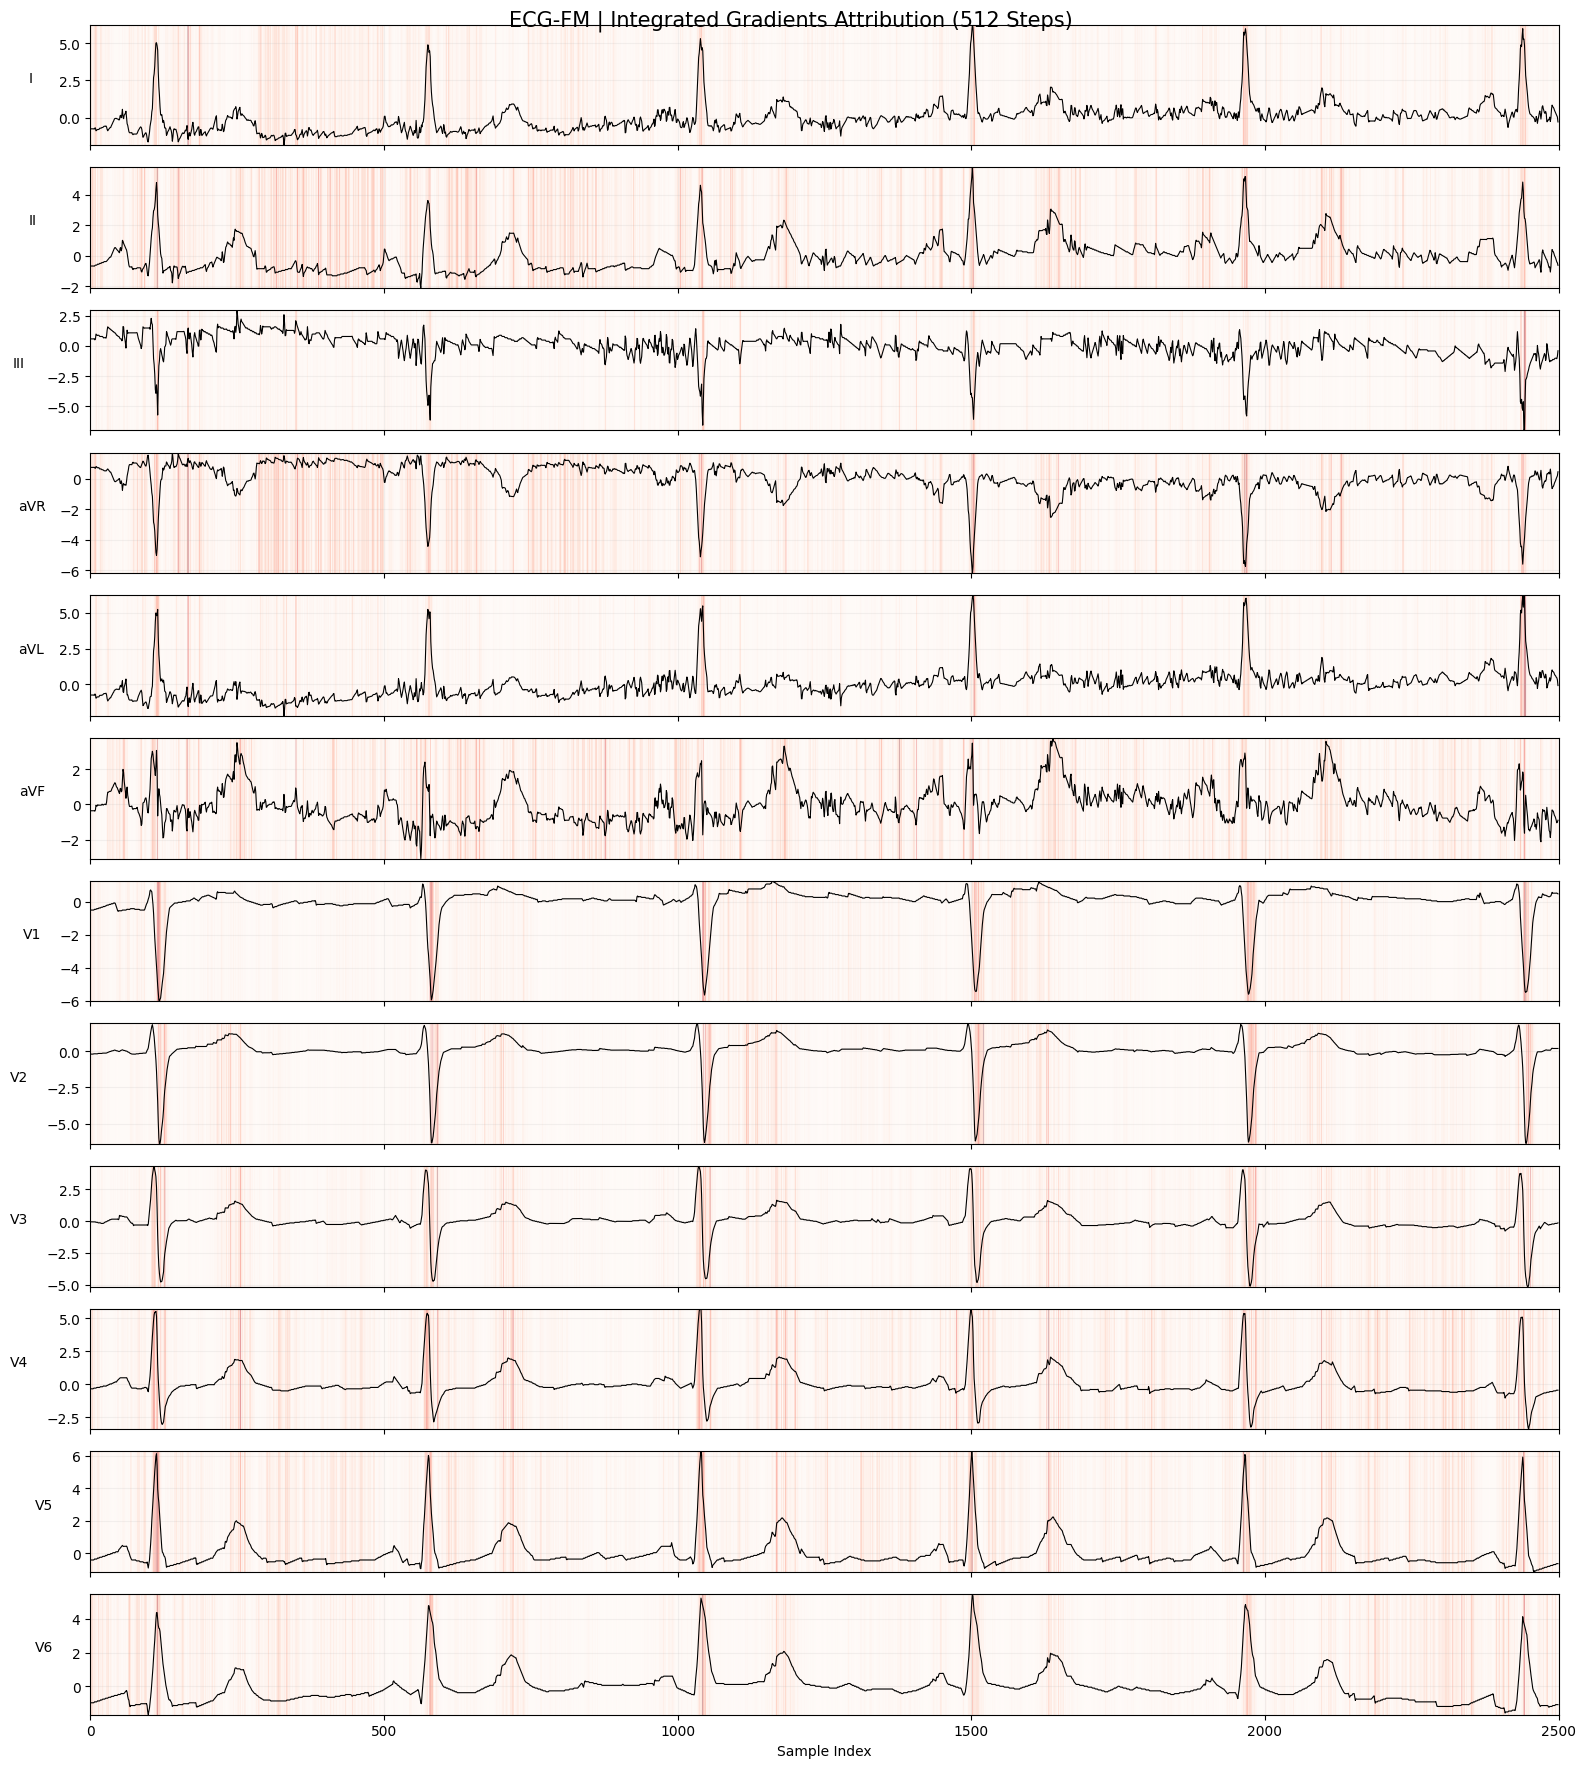

In [72]:
import numpy as np
import matplotlib.pyplot as plt

ecg = ecg_tensor.detach().cpu().numpy()[0]
importance = attr.detach().abs().cpu().numpy()[0]

lead_names = [
    "I", "II", "III", "aVR", "aVL", "aVF",
    "V1", "V2", "V3", "V4", "V5", "V6"
]

fig, axes = plt.subplots(
    12, 1, figsize=(16, 18), sharex=True
)

for i, ax in enumerate(axes):
    signal = ecg[i]
    heat = importance[i]

    heat = heat / (heat.max() + 1e-12)

    ax.plot(signal, color="black", linewidth=0.8)

    ax.imshow(
        heat[np.newaxis, :],
        aspect="auto",
        cmap="Reds",
        extent=[0, len(signal), signal.min(), signal.max()],
        alpha=0.45,
        origin="lower"
    )

    ax.set_ylabel(lead_names[i], rotation=0, labelpad=20)
    ax.grid(alpha=0.15)

axes[-1].set_xlabel("Sample Index")

plt.suptitle(
    "ECG-FM | Integrated Gradients Attribution (512 Steps)",
    fontsize=15
)
plt.tight_layout()
plt.show()

In [73]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from IPython.display import display
import ipywidgets as widgets

# ========= DATA =========

ecg = ecg_tensor.detach().cpu().numpy()[0]
ig_attr = attr.detach().cpu().numpy()[0]
importance = np.abs(ig_attr)

lead_names = [
    "I", "II", "III", "aVR", "aVL", "aVF",
    "V1", "V2", "V3", "V4", "V5", "V6"
]

lead_groups = {
    "Inferior (II, III, aVF)": ["II", "III", "aVF"],
    "Anterior (V1–V4)": ["V1", "V2", "V3", "V4"],
    "Lateral (I, aVL, V5, V6)": ["I", "aVL", "V5", "V6"],
    "All 12 Leads": lead_names
}

# Set this to the sampling rate of x_norm
FS = 500

time = np.arange(ecg.shape[1]) / FS

# Shared scale across ALL leads
ig_scale = max(np.percentile(importance, 99.5), 1e-12)
normalized_ig = np.clip(importance / ig_scale, 0, 1)


# ========= DASHBOARD =========

def show_ecg_dashboard(
    group="Inferior (II, III, aVF)",
    show_attribution=True,
    focus_start=0.0,
    focus_duration=2.0
):
    selected = lead_groups[group]
    indices = [lead_names.index(name) for name in selected]

    fig = plt.figure(figsize=(16, 11), layout="constrained")
    fig.patch.set_facecolor("#FAFAFA")

    gs = fig.add_gridspec(
        2, 2,
        height_ratios=[2.1, 1.4],
        width_ratios=[3.4, 1.1]
    )

    # ========= 1. ECG OVERVIEW =========

    overview = gs[0, 0].subgridspec(
        12, 1,
        hspace=0.12
    )

    for i, name in enumerate(lead_names):
        ax = fig.add_subplot(overview[i, 0])

        ax.plot(
            time, ecg[i],
            color="#263238",
            linewidth=0.75
        )

        if name in selected:
            ax.set_facecolor("#FFF3E8")
            ax.spines["left"].set_color("#E47736")
            ax.spines["left"].set_linewidth(3)
        else:
            ax.set_facecolor("white")

        ax.set_ylabel(
            name, rotation=0,
            labelpad=19, fontsize=9
        )

        ax.set_xlim(time[0], time[-1])
        ax.set_yticks([])

        if i != 11:
            ax.set_xticks([])
        else:
            ax.set_xlabel("Time (s)")

        ax.grid(alpha=0.1)

    # ========= 2. FOCUS VIEW =========

    focus_grid = gs[1, 0].subgridspec(
        len(indices), 1,
        hspace=0.15
    )

    end = min(focus_start + focus_duration, time[-1])

    for row, i in enumerate(indices):
        ax = fig.add_subplot(focus_grid[row, 0])

        signal = ecg[i]
        heat = normalized_ig[i]

        ax.plot(
            time,
            signal,
            color="#1F2937",
            linewidth=1.15,
            zorder=3
        )

        ax.set_xlim(focus_start, end)

        if show_attribution:
            ymin = np.min(signal)
            ymax = np.max(signal)
            padding = max((ymax - ymin) * 0.12, 0.1)

            ax.imshow(
                heat[np.newaxis, :],
                extent=[
                    time[0], time[-1],
                    ymin - padding,
                    ymax + padding
                ],
                aspect="auto",
                cmap="OrRd",
                vmin=0,
                vmax=1,
                interpolation="nearest",
                alpha=0.45,
                origin="lower",
                zorder=1
            )

        ax.set_ylabel(
            lead_names[i],
            rotation=0,
            labelpad=20,
            weight="bold"
        )

        ax.grid(alpha=0.15)

        if row == len(indices) - 1:
            ax.set_xlabel("Time (seconds)")
        else:
            ax.tick_params(labelbottom=False)

    # ========= 3. ATTRIBUTION SUMMARY =========

    ax_sum = fig.add_subplot(gs[:, 1])

    lead_scores = importance.sum(axis=1)
    total = lead_scores.sum()

    percentages = (
        100 * lead_scores / total
        if total > 0 else np.zeros_like(lead_scores)
    )

    order = np.argsort(percentages)[::-1]

    sorted_names = [lead_names[i] for i in order]
    sorted_values = percentages[order]

    colors = [
        "#E47736" if name in selected else "#B8C4CC"
        for name in sorted_names
    ]

    bars = ax_sum.barh(
        sorted_names,
        sorted_values,
        color=colors
    )

    ax_sum.invert_yaxis()
    ax_sum.set_xlabel("Absolute IG Share (%)")
    ax_sum.set_title(
        "Attribution by Lead",
        loc="left",
        weight="bold",
        fontsize=12
    )

    ax_sum.spines[["top", "right"]].set_visible(False)
    ax_sum.grid(axis="x", alpha=0.12)
    ax_sum.set_axisbelow(True)

    ax_sum.set_xlim(0, max(sorted_values) * 1.25 + 1)

    for bar, value in zip(bars, sorted_values):
        ax_sum.text(
            value + 0.3,
            bar.get_y() + bar.get_height()/2,
            f"{value:.1f}%",
            va="center",
            fontsize=9
        )

    fig.suptitle(
        "ECG-FM | Explainability Dashboard",
        fontsize=19,
        fontweight="bold"
    )

    fig.text(
        0.02, 0.955,
        "Experimental pretrained-feature attribution • "
        "Not a STEMI classification explanation",
        fontsize=10,
        color="#666666"
    )

    plt.show()


# ========= INTERACTIVE CONTROLS =========

max_time = float(time[-1])

group_widget = widgets.Dropdown(
    options=list(lead_groups),
    value="Inferior (II, III, aVF)",
    description="Lead group:",
    style={"description_width": "initial"}
)

ig_widget = widgets.Checkbox(
    value=True,
    description="Show IG heatmap"
)

start_widget = widgets.FloatSlider(
    value=0,
    min=0,
    max=max(0, max_time - 1),
    step=0.5,
    description="Start (s):",
    style={"description_width": "initial"}
)

duration_widget = widgets.FloatSlider(
    value=2,
    min=0.5,
    max=min(5, max_time),
    step=0.5,
    description="Window (s):",
    style={"description_width": "initial"}
)

controls = widgets.VBox([
    group_widget,
    ig_widget,
    start_widget,
    duration_widget
])

output = widgets.interactive_output(
    show_ecg_dashboard,
    {
        "group": group_widget,
        "show_attribution": ig_widget,
        "focus_start": start_widget,
        "focus_duration": duration_widget
    }
)

display(controls, output)

Output()

In [74]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

ecg = ecg_tensor.detach().cpu().numpy()[0]
importance = np.abs(attr.detach().cpu().numpy()[0])

lead_names = [
    "I", "II", "III", "aVR", "aVL", "aVF",
    "V1", "V2", "V3", "V4", "V5", "V6"
]

groups = {
    "Inferior": ["II", "III", "aVF"],
    "Anterior": ["V1", "V2", "V3", "V4"],
    "Lateral": ["I", "aVL", "V5", "V6"],
    "All Leads": lead_names
}

FS = 500  # เปลี่ยนถ้า sampling rate จริงไม่ใช่ 500 Hz
n = ecg.shape[1]
t = np.arange(n) / FS

# สเกลความเข้มของ IG ร่วมกันทั้ง 12 Leads
ig_max = max(np.percentile(importance, 99.5), 1e-12)
heat = np.clip(importance / ig_max, 0, 1)


def focus_ecg(group="Inferior", window=0.8, mode="Highest IG"):
    selected = groups[group]
    indices = [lead_names.index(name) for name in selected]

    window_samples = min(n, max(2, int(window * FS)))

    # รวม Absolute IG ตามเวลาจาก Leads ที่เลือก
    importance_by_time = importance[indices].sum(axis=0)

    # คำนวณ IG รวมในแต่ละหน้าต่าง
    scores = np.convolve(
        importance_by_time,
        np.ones(window_samples),
        mode="valid"
    )

    if mode == "Highest IG":
        start_idx = int(np.argmax(scores))
    else:
        start_idx = 0

    end_idx = start_idx + window_samples

    # ขยายบริเวณที่เลือกให้เต็มกราฟ
    fig, axes = plt.subplots(
        len(indices), 1,
        figsize=(17, 3.6 * len(indices)),
        sharex=True,
        squeeze=False,
        constrained_layout=True
    )

    axes = axes.ravel()

    for ax, i in zip(axes, indices):
        signal = ecg[i, start_idx:end_idx]
        time_slice = t[start_idx:end_idx]
        heat_slice = heat[i, start_idx:end_idx]

        ymin, ymax = signal.min(), signal.max()
        pad = max((ymax - ymin) * 0.15, 0.1)

        ax.imshow(
            heat_slice[np.newaxis, :],
            extent=[
                time_slice[0],
                time_slice[-1] + 1/FS,
                ymin - pad,
                ymax + pad
            ],
            cmap="OrRd",
            vmin=0,
            vmax=1,
            alpha=0.45,
            aspect="auto",
            interpolation="nearest",
            origin="lower"
        )

        ax.plot(
            time_slice,
            signal,
            color="#17212B",
            linewidth=1.6
        )

        ax.set_ylim(ymin - pad, ymax + pad)
        ax.set_ylabel(lead_names[i], fontsize=14, weight="bold")
        ax.grid(alpha=0.14)

    axes[-1].set_xlabel("Time (seconds)", fontsize=12)

    fig.suptitle(
        f"ECG-FM XAI Focus | {group} | "
        f"{t[start_idx]:.2f}–{(end_idx / FS):.2f} s",
        fontsize=17,
        weight="bold"
    )

    plt.show()

    total = importance[indices].sum()
    selected_ig = importance[indices, start_idx:end_idx].sum()

    print(
        f"Selected interval: {start_idx}–{end_idx - 1} samples "
        f"({start_idx / FS:.3f}–{end_idx / FS:.3f} seconds)"
    )
    print(
        f"Absolute IG captured within selected leads: "
        f"{100 * selected_ig / max(total, 1e-12):.2f}%"
    )
    print(
        "Note: High IG is not equivalent to ST elevation or STEMI."
    )


widgets.interact(
    focus_ecg,
    group=widgets.Dropdown(
        options=list(groups),
        value="Inferior",
        description="Lead group:"
    ),
    window=widgets.FloatSlider(
        value=0.8,
        min=0.3,
        max=2.0,
        step=0.1,
        description="Window (s):"
    ),
    mode=widgets.Dropdown(
        options=["Highest IG", "Beginning"],
        description="Focus:"
    )
)

interactive(children=(Dropdown(description='Lead group:', options=('Inferior', 'Anterior', 'Lateral', 'All Lea…

<function __main__.focus_ecg(group='Inferior', window=0.8, mode='Highest IG')>

In [75]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d, binary_closing
from scipy.signal import find_peaks
import ipywidgets as widgets
from IPython.display import display

# ===== DATA =====
ecg = ecg_tensor.detach().cpu().numpy()[0]
ig = np.abs(attr.detach().cpu().numpy()[0])

FS = 500  # ตรวจว่าตรงกับ sampling rate จริง
N = ecg.shape[1]
time = np.arange(N) / FS

LEADS = ["I", "II", "III", "aVR", "aVL", "aVF",
         "V1", "V2", "V3", "V4", "V5", "V6"]

GROUPS = {
    "Inferior": ["II", "III", "aVF"],
    "Anterior": ["V1", "V2", "V3", "V4"],
    "Lateral": ["I", "aVL", "V5", "V6"]
}

def top_regions(values, threshold=85, smooth_ms=25):
    """Find contiguous regions of high IG (visualization only)."""
    smoothed = gaussian_filter1d(
        values.astype(float),
        sigma=max(1, FS * smooth_ms / 1000)
    )

    cutoff = np.percentile(smoothed, threshold)
    mask = smoothed >= cutoff
    mask = binary_closing(mask, structure=np.ones(max(1, int(FS * .015))))

    edges = np.diff(np.r_[False, mask, False].astype(int))
    starts = np.where(edges == 1)[0]
    ends = np.where(edges == -1)[0]
    return list(zip(starts, ends))

def candidate_landmarks(signal):
    """
    Exploratory R-peak candidates from amplitude.
    NOT validated clinical delineation.
    """
    filtered = gaussian_filter1d(signal.astype(float), sigma=2)
    energy = np.abs(filtered - np.median(filtered))
    peaks, _ = find_peaks(
        energy,
        distance=int(.35 * FS),
        prominence=max(np.std(energy) * 1.5, 1e-8)
    )
    return peaks

def view_clinical_xai(
    group="Inferior",
    window=0.8,
    threshold=85,
    show_candidates=False
):
    leads = GROUPS[group]
    ids = [LEADS.index(l) for l in leads]
    width = int(window * FS)

    # Pick highest IG window among the selected leads.
    combined = ig[ids].sum(axis=0)
    moving = np.convolve(combined, np.ones(width), mode="valid")
    start = int(np.argmax(moving))
    end = min(start + width, N)

    fig, axes = plt.subplots(
        len(ids), 1,
        figsize=(18, 4.2 * len(ids)),
        sharex=True,
        constrained_layout=True
    )
    axes = np.atleast_1d(axes)

    for ax, idx in zip(axes, ids):
        signal = ecg[idx]
        ax.plot(time[start:end], signal[start:end],
                color="#17212B", linewidth=2)

        # Top IG Regions, based on the full lead.
        for a, b in top_regions(ig[idx], threshold):
            left, right = max(a, start), min(b, end)
            if left < right:
                ax.axvspan(
                    left / FS, right / FS,
                    color="#E74C3C",
                    alpha=0.27,
                    linewidth=0
                )

        if show_candidates:
            peaks = candidate_landmarks(signal)
            for p in peaks:
                if start <= p < end:
                    ax.axvline(
                        p / FS, color="#2563EB",
                        linestyle="--", alpha=.65
                    )
                    ax.text(
                        p / FS, ax.get_ylim()[1],
                        "Peak candidate",
                        color="#2563EB", fontsize=9,
                        ha="center", va="top"
                    )

        ax.set_ylabel(LEADS[idx], fontsize=15, weight="bold")
        ax.set_xlim(start / FS, end / FS)
        ax.grid(alpha=0.12)

    axes[-1].set_xlabel("Time (seconds)", fontsize=12)
    fig.suptitle(
        f"Clinical XAI Explorer | {group} | "
        f"{start/FS:.2f}–{end/FS:.2f}s",
        fontsize=19, weight="bold"
    )
    plt.show()

    print("Red = high absolute IG (pretrained-feature target)")
    print("Blue dashed = exploratory peak candidate, NOT validated R-peak")
    print("No automatic J-point/ST/T-wave delineation is asserted.")

widgets.interact(
    view_clinical_xai,
    group=widgets.Dropdown(
        options=list(GROUPS), value="Inferior"
    ),
    window=widgets.FloatSlider(
        value=.8, min=.4, max=2.0, step=.1,
        description="Window (s)"
    ),
    threshold=widgets.IntSlider(
        value=85, min=70, max=95, step=5,
        description="Top IG percentile"
    ),
    show_candidates=widgets.Checkbox(
        value=False,
        description="Show exploratory peak candidates"
    )
)

interactive(children=(Dropdown(description='group', options=('Inferior', 'Anterior', 'Lateral'), value='Inferi…

<function __main__.view_clinical_xai(group='Inferior', window=0.8, threshold=85, show_candidates=False)>

In [76]:
%pip -q install neurokit2

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 693.1/693.1 kB 19.2 MB/s eta 0:00:00


In [77]:
import numpy as np
import matplotlib.pyplot as plt
import neurokit2 as nk
import ipywidgets as widgets
from IPython.display import display
from scipy.ndimage import gaussian_filter1d, binary_closing

# ===== INPUTS =====
FS = 500  # ต้องตรงกับ sampling rate ของ ecg_tensor จริง

ecg = ecg_tensor.detach().cpu().numpy()[0]
ig = np.abs(attr.detach().cpu().numpy()[0])

LEADS = ["I", "II", "III", "aVR", "aVL", "aVF",
         "V1", "V2", "V3", "V4", "V5", "V6"]

GROUPS = {
    "Inferior": ["II", "III", "aVF"],
    "Anterior": ["V1", "V2", "V3", "V4"],
    "Lateral": ["I", "aVL", "V5", "V6"]
}

N = ecg.shape[1]
time = np.arange(N) / FS

assert ecg.shape == ig.shape, "ECG and IG shapes must match"
assert ecg.shape[0] == 12, "Expected 12 ECG leads"

# ===== DETECT CLINICAL LANDMARKS =====

# Detect shared R peaks from Lead II.
# Detection uses ECG, NOT IG.
reference = nk.ecg_clean(ecg[1], sampling_rate=FS)
_, peak_info = nk.ecg_peaks(reference, sampling_rate=FS)
rpeaks = np.asarray(peak_info["ECG_R_Peaks"], dtype=int)

if len(rpeaks) < 2:
    raise ValueError(
        "Too few R peaks for reliable automatic delineation. "
        "Check the ECG signal, sampling rate, and recording length."
    )

print("Detected R peaks:", rpeaks.tolist())

# Delineate each lead independently using common R timing.
landmarks = {}
warnings = {}

for lead_idx, name in enumerate(LEADS):
    try:
        cleaned = nk.ecg_clean(ecg[lead_idx], sampling_rate=FS)

        _, waves = nk.ecg_delineate(
            cleaned,
            rpeaks=rpeaks,
            sampling_rate=FS,
            method="dwt",
            show=False
        )

        landmarks[name] = waves

    except Exception as e:
        landmarks[name] = {}
        warnings[name] = str(e)

def valid_index(value):
    try:
        if value is None or not np.isfinite(value):
            return None
        value = int(value)
        return value if 0 <= value < N else None
    except (TypeError, ValueError):
        return None

def get_wave(waves, key, beat):
    values = waves.get(key, [])
    if beat >= len(values):
        return None
    return valid_index(values[beat])

def high_ig_regions(values, percentile=90):
    smooth = gaussian_filter1d(
        values.astype(float),
        sigma=max(1, int(FS * 0.012))
    )

    cutoff = np.percentile(smooth, percentile)
    mask = smooth >= cutoff

    mask = binary_closing(
        mask,
        structure=np.ones(max(1, int(FS * .012)))
    )

    edges = np.diff(np.r_[False, mask, False].astype(int))
    starts = np.where(edges == 1)[0]
    ends = np.where(edges == -1)[0]

    return list(zip(starts, ends))

def clinical_xai_viewer(
    group="Inferior",
    window=1.2,
    ig_percentile=90,
    show_qrs=True,
    show_st=True,
    show_ig=True
):
    chosen = GROUPS[group]
    ids = [LEADS.index(name) for name in chosen]

    width = min(N, max(2, int(window * FS)))

    # Find highest-IG window among chosen leads.
    combined = ig[ids].sum(axis=0)

    scores = np.convolve(
        combined,
        np.ones(width),
        mode="valid"
    )

    start = int(np.argmax(scores))
    end = start + width

    fig, axes = plt.subplots(
        len(ids), 1,
        figsize=(18, 4.3 * len(ids)),
        sharex=True,
        constrained_layout=True
    )

    axes = np.atleast_1d(axes)

    for ax, idx in zip(axes, ids):
        name = LEADS[idx]
        signal = ecg[idx]
        waves = landmarks[name]

        # ===== RAW ECG =====
        ax.plot(
            time[start:end],
            signal[start:end],
            color="#17212B",
            linewidth=1.8,
            zorder=5
        )

        # ===== XAI REGIONS =====
        if show_ig:
            regions = high_ig_regions(
                ig[idx],
                percentile=ig_percentile
            )

            for a, b in regions:
                a2 = max(a, start)
                b2 = min(b, end)

                if a2 < b2:
                    ax.axvspan(
                        a2 / FS,
                        b2 / FS,
                        color="#EF4444",
                        alpha=0.24,
                        zorder=2
                    )

        # ===== CLINICAL LANDMARKS =====
        for beat, r in enumerate(rpeaks):
            qrs_on = get_wave(waves, "ECG_R_Onsets", beat)
            qrs_off = get_wave(waves, "ECG_R_Offsets", beat)
            t_on = get_wave(waves, "ECG_T_Onsets", beat)

            # QRS boundary
            if (
                show_qrs
                and qrs_on is not None
                and qrs_off is not None
                and qrs_on < qrs_off
                and 0.02 <= (qrs_off - qrs_on) / FS <= 0.20
            ):
                ax.axvspan(
                    qrs_on / FS,
                    qrs_off / FS,
                    color="#3B82F6",
                    alpha=0.15,
                    zorder=1
                )

            # J-point candidate = estimated QRS offset
            if (
                show_st
                and qrs_off is not None
                and start <= qrs_off < end
            ):
                ax.axvline(
                    qrs_off / FS,
                    color="#059669",
                    linestyle="--",
                    linewidth=1.4,
                    alpha=0.8,
                    zorder=4
                )

            # ST candidate region: QRS offset -> T onset
            # Reject implausible or reversed intervals.
            if (
                show_st
                and qrs_off is not None
                and t_on is not None
                and qrs_off < t_on
                and 0.02 <= (t_on - qrs_off) / FS <= 0.35
            ):
                ax.axvspan(
                    qrs_off / FS,
                    t_on / FS,
                    color="#10B981",
                    alpha=0.20,
                    zorder=1
                )

        ax.set_ylabel(
            name,
            fontsize=15,
            fontweight="bold"
        )

        ax.set_xlim(start / FS, end / FS)
        ax.grid(alpha=0.12)

    axes[-1].set_xlabel("Time (seconds)", fontsize=12)

    fig.suptitle(
        f"ECG Clinical XAI | {group} | "
        f"{start/FS:.2f}-{end/FS:.2f} s",
        fontsize=18,
        fontweight="bold"
    )

    plt.show()

    print(
        f"Focus: samples {start} to {end-1} "
        f"({start/FS:.3f}-{end/FS:.3f} s)"
    )
    print("Blue: estimated QRS")
    print("Green dashed: candidate J-point (QRS offset)")
    print("Green region: estimated ST segment")
    print("Red: top absolute IG regions")

    for name in chosen:
        if name in warnings:
            print(f"Warning: {name}: {warnings[name]}")

    print(
        "All clinical landmarks are automatic candidates; "
        "manual verification is required."
    )

# ===== INTERACTIVE =====
widgets.interact(
    clinical_xai_viewer,

    group=widgets.Dropdown(
        options=list(GROUPS),
        value="Inferior",
        description="Lead group:"
    ),

    window=widgets.FloatSlider(
        value=1.2,
        min=0.5,
        max=2.0,
        step=0.1,
        description="Window (s):"
    ),

    ig_percentile=widgets.IntSlider(
        value=90,
        min=70,
        max=98,
        step=2,
        description="IG threshold:"
    ),

    show_qrs=widgets.Checkbox(
        value=True,
        description="Show QRS"
    ),

    show_st=widgets.Checkbox(
        value=True,
        description="Show J-point / ST"
    ),

    show_ig=widgets.Checkbox(
        value=True,
        description="Show IG"
    )
)

Detected R peaks: [575, 1039, 1501, 1966, 2438]


interactive(children=(Dropdown(description='Lead group:', options=('Inferior', 'Anterior', 'Lateral'), value='…

<function __main__.clinical_xai_viewer(group='Inferior', window=1.2, ig_percentile=90, show_qrs=True, show_st=True, show_ig=True)>

In [78]:
import contextlib
import warnings
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from scipy.ndimage import gaussian_filter1d
import neurokit2 as nk
from captum.attr import IntegratedGradients, DeepLift
from IPython.display import display

# Reuse the original loaded PTB-XL recording, checkpoint and crop.
full_ecg = np.asarray(raw, dtype=np.float32)
N = display_ecg.shape[1]
time = np.arange(N) / FS
GROUPS = {'Inferior':['II','III','aVF'], 'Anterior':['V1','V2','V3','V4'],
          'Lateral':['I','aVL','V5','V6'], 'All Leads':LEADS}
TARGET_KEY = 'features'
TARGET_REDUCTION = 'abs_mean'
CAM_LAYER = 'feature_extractor'
CAM_LAYOUT = 'BCT'
USE_MANUAL_LANDMARKS = False
MANUAL_INTERVALS = []
ST_PERCENTILE = 75
MAX_ST_REGIONS_PER_LEAD = 3
# Original ECG-FM pretrained representations are not disease classification logits.
print('Integration inputs:', full_ecg.shape, display_ecg.shape,
      'ECG-FM loaded:', model is not None)


Integration inputs: (12, 5000) (12, 2500) ECG-FM loaded: True


,lead,beat,r,qrs_on,start,end,t_peak,origin
0,I,0,575,548,597,695,718,DWT candidate
1,I,1,1039,1015,1063,1164,1180,DWT candidate
2,I,2,1501,1472,1543,1628,1640,DWT candidate
3,II,0,575,550,597,692,717,DWT candidate
4,II,1,1039,973,1063,1147,1180,DWT candidate
5,II,2,1501,1474,1543,1628,1641,DWT candidate
6,II,3,1966,1910,2004,2077,2107,DWT candidate
7,III,1,1039,987,1053,1078,1085,DWT candidate
8,III,2,1501,1476,1516,1633,1649,DWT candidate
9,III,4,2438,2367,2454,2472,2481,DWT candidate


Rejected full-record beats: 33 lead errors: {}


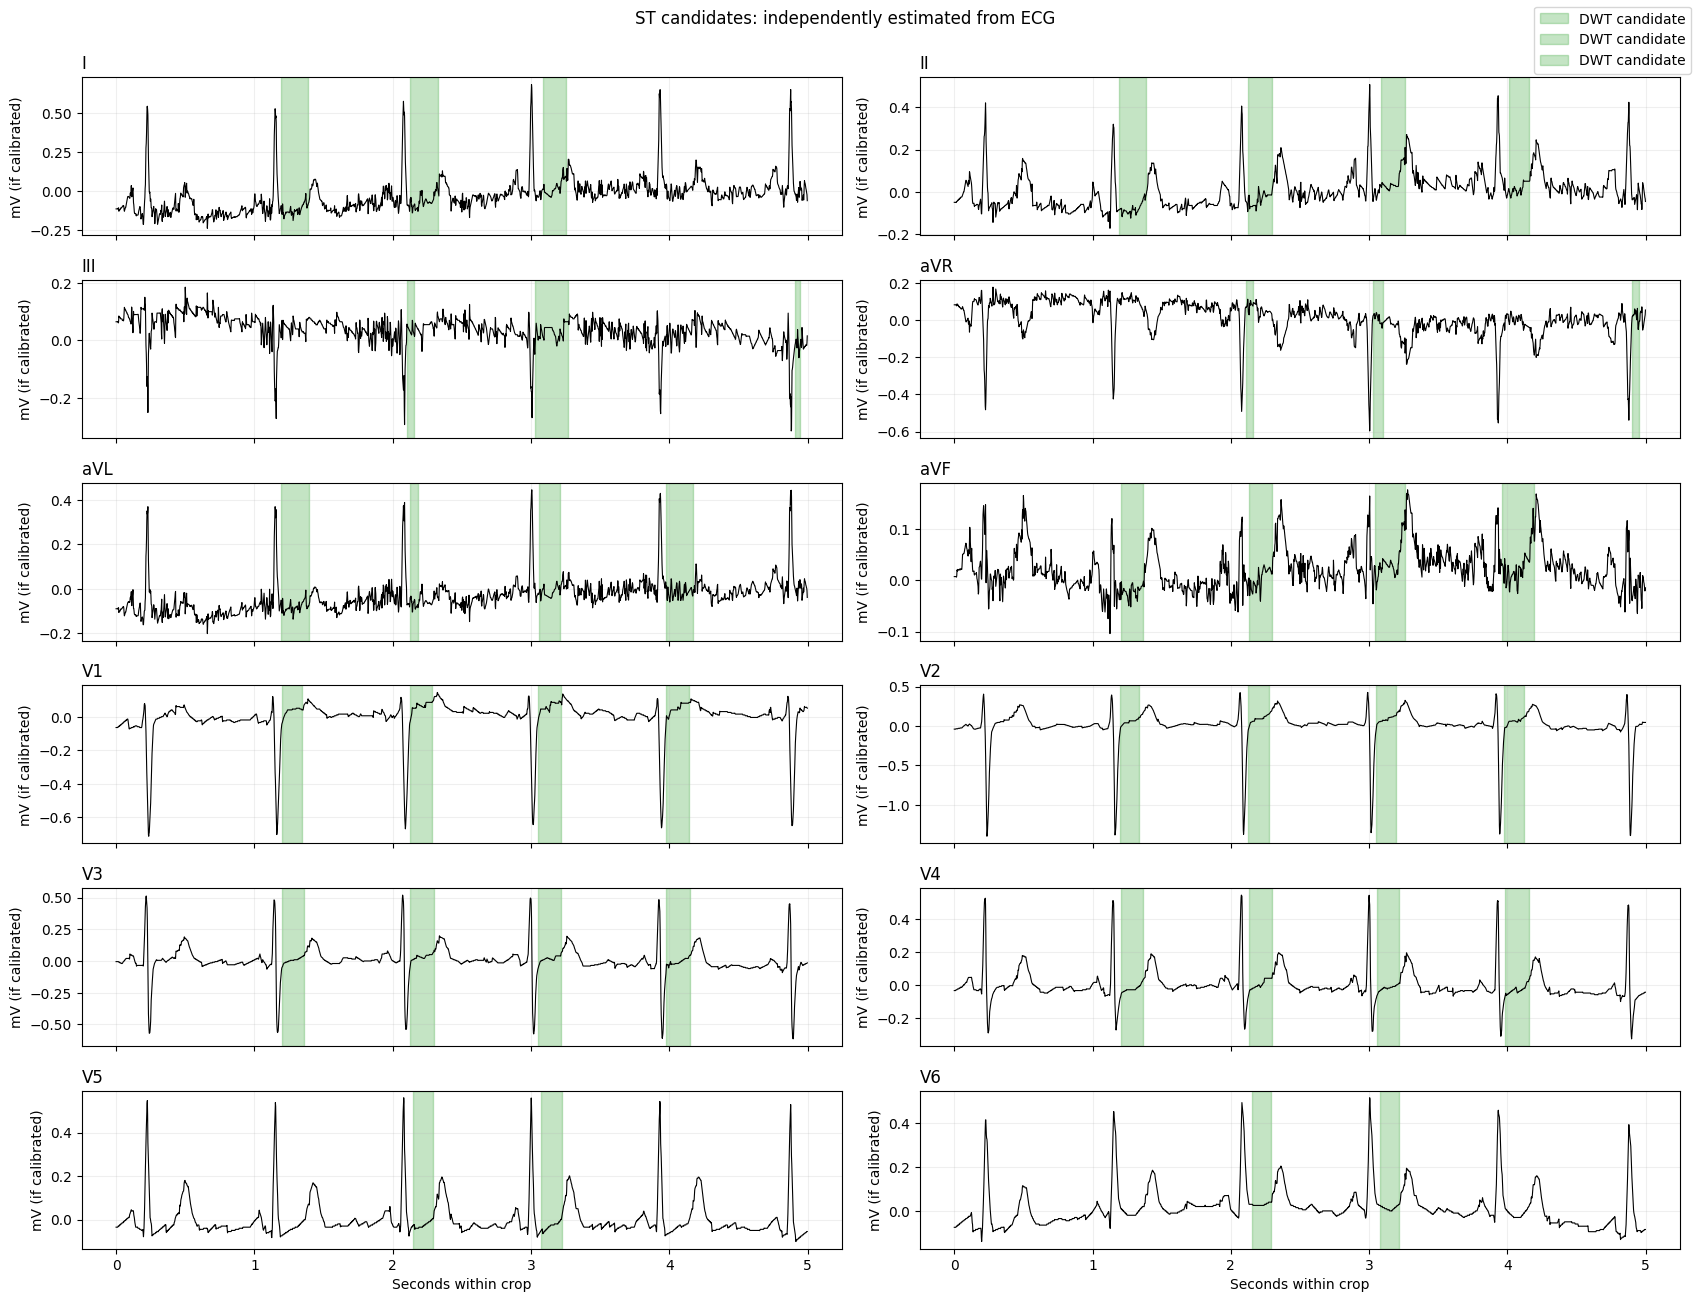

In [79]:
def wave_index(waves, key, beat, n_beats, length):
    values = waves.get(key, [])
    if len(values) != n_beats:  # never align a shortened vector by guessing
        return None
    v = values[beat]
    try:
        return int(v) if np.isfinite(v) and float(v).is_integer() and 0 <= v < length else None
    except (TypeError, ValueError):
        return None

def make_st_candidates(waves, rpeaks, length, fs, lead,
                       qrs_limits=(.025,.20), st_limits=(.02,.30), margin_s=.15):
    accepted, rejected = [], []
    rpeaks = np.asarray(rpeaks, dtype=int)
    for b, r in enumerate(rpeaks):
        get = lambda k: wave_index(waves, k, b, len(rpeaks), length)
        on, off, ton, tp = [get(k) for k in
                           ('ECG_R_Onsets','ECG_R_Offsets','ECG_T_Onsets','ECG_T_Peaks')]
        reason = None
        if any(v is None for v in (on, off, ton, tp)):
            reason = 'missing or misaligned wave boundary'
        elif b + 1 >= len(rpeaks):
            reason = 'no following R peak'
        elif not (on < r < off < ton < tp < rpeaks[b+1]):
            reason = 'invalid beat ordering'
        elif on < round(margin_s*fs) or tp >= length-round(margin_s*fs):
            reason = 'recording edge'
        elif not qrs_limits[0] <= (off-on)/fs <= qrs_limits[1]:
            reason = 'QRS duration outside configured limits'
        elif not st_limits[0] <= (ton-off)/fs <= st_limits[1]:
            reason = 'ST duration outside configured limits'
        if reason:
            rejected.append(dict(lead=lead, beat=b, r=int(r), reason=reason))
        else:
            accepted.append(dict(lead=lead, beat=b, r=int(r), qrs_on=on,
                                 start=off, end=ton, t_peak=tp, origin='DWT candidate'))
    return accepted, rejected

def delineate_record(ecg_mv, fs, reference_lead='II', method='dwt'):
    ref = nk.ecg_clean(ecg_mv[LEADS.index(reference_lead)], sampling_rate=fs)
    _, info = nk.ecg_peaks(ref, sampling_rate=fs)
    rp = np.asarray(info['ECG_R_Peaks'], dtype=int)
    if len(rp) < 3:
        raise ValueError('Fewer than three R peaks: use a longer record or reviewed intervals')
    landmarks, accepted, rejected, errors = {}, [], [], {}
    for i, name in enumerate(LEADS):
        if np.std(ecg_mv[i]) < 1e-8:
            errors[name] = 'Flat lead'; continue
        try:
            clean = nk.ecg_clean(ecg_mv[i], sampling_rate=fs)
            _, waves = nk.ecg_delineate(clean, rpeaks=rp, sampling_rate=fs,
                                      method=method, check=False, show=False)
            landmarks[name] = waves
            good, bad = make_st_candidates(waves, rp, ecg_mv.shape[1], fs, name)
            accepted.extend(good); rejected.extend(bad)
        except (ValueError, IndexError, ZeroDivisionError) as exc:
            errors[name] = f'{type(exc).__name__}: {exc}'
    return rp, landmarks, accepted, rejected, errors

rpeaks_full, landmarks, full_candidates, rejections, delineation_errors = delineate_record(full_ecg, FS)
rpeaks = rpeaks_full[(rpeaks_full >= start_sample) & (rpeaks_full < end_sample)] - start_sample
st_candidates = []
for c in full_candidates:
    if start_sample <= c['qrs_on'] and c['t_peak'] < end_sample:
        d = c.copy()
        for key in ('r','qrs_on','start','end','t_peak'): d[key] -= start_sample
        st_candidates.append(d)

def manual_candidates(intervals):
    result = []
    for b, item in enumerate(intervals):
        if item['lead'] not in LEADS: raise ValueError('Unknown manual lead')
        a, z = float(item['start_s']), float(item['end_s'])
        if not np.isfinite([a,z]).all() or not 0 <= a < z <= N/FS:
            raise ValueError('Manual interval outside crop')
        result.append(dict(lead=item['lead'], beat=b, start=round(a*FS), end=round(z*FS),
                           origin='Reviewed manual interval'))
    return result
if USE_MANUAL_LANDMARKS:
    if not MANUAL_INTERVALS: raise ValueError('Manual mode requires reviewed intervals')
    st_candidates = manual_candidates(MANUAL_INTERVALS)
clinical_intervals = [dict(lead=c['lead'], start_s=c['start']/FS, end_s=c['end']/FS,
                           color='tab:green', label=c['origin']) for c in st_candidates]
display(pd.DataFrame(st_candidates))
print('Rejected full-record beats:', len(rejections), 'lead errors:', delineation_errors)
plot_ecg(display_ecg, clinical_intervals, 'ST candidates: independently estimated from ECG'); plt.show()

In [80]:
@contextlib.contextmanager
def attribution_context(network):
    modes = [(m, m.training) for m in network.modules()]
    mults = [(m, m.feature_grad_mult) for m in network.modules() if hasattr(m, 'feature_grad_mult')]
    try:
        network.eval()
        for m, _ in mults: m.feature_grad_mult = 1.0
        with torch.enable_grad(): yield
    finally:
        for m, v in mults: m.feature_grad_mult = v
        for m, v in modes: m.training = v

class FeatureTarget(torch.nn.Module):
    def __init__(self, backbone, key='features', reduction='abs_mean'):
        super().__init__(); self.backbone = backbone; self.key = key; self.reduction = reduction
    def forward(self, x):
        out = self.backbone(source=x, mask=False, features_only=True)
        if self.key not in out: raise KeyError(f'Target key {self.key!r} absent; keys={list(out)}')
        z = out[self.key]
        if z.ndim != 3 or z.shape[0] != x.shape[0]:
            raise ValueError('Target expects batch-first [B,T,C] features')
        if not torch.isfinite(z).all(): raise ValueError('Non-finite target features')
        if self.reduction == 'abs_mean': return z.float().abs().mean(dim=(1,2))
        if self.reduction == 'square_mean': return z.float().square().mean(dim=(1,2))
        raise ValueError('Unsupported reduction')

# A downstream classifier adapter must return one verified pre-sigmoid class logit per example.
# Replace FeatureTarget with that adapter; do not relabel this feature score as STEMI.
target = FeatureTarget(model, TARGET_KEY, TARGET_REDUCTION) if model is not None else None

class TemporalGradCAM:
    def __init__(self, target, layer, layout='BCT', output_selector=None):
        if layout not in ('BCT','BTC','TBC'): raise ValueError('Specify BCT, BTC or TBC')
        self.target, self.layer, self.layout = target, layer, layout
        self.output_selector = output_selector
    def __call__(self, x):
        saved = []
        def capture(module, inputs, output):
            z = self.output_selector(output) if self.output_selector else output
            if not isinstance(z, torch.Tensor) or z.ndim != 3:
                raise ValueError('CAM layer must resolve to a rank-3 Tensor; specify output_selector for dict/tuple')
            saved.append(z)  # retain graph, never detach here
        handle = self.layer.register_forward_hook(capture)
        try:
            with attribution_context(self.target):
                inp = x.detach().clone().requires_grad_(True)
                scores = self.target(inp)
                if scores.shape != (x.shape[0],): raise ValueError('Target must return [B] scores')
                if len(saved) != 1: raise ValueError('CAM layer must execute exactly once')
                activation = saved[0]
                if not activation.requires_grad: raise RuntimeError('CAM activation has no gradient graph')
                grad = torch.autograd.grad(scores.sum(), activation, allow_unused=True)[0]
                if grad is None: raise RuntimeError('CAM layer is disconnected from this target')
                def bct(z):
                    return z if self.layout == 'BCT' else (z.transpose(1,2) if self.layout == 'BTC' else z.permute(1,2,0))
                a, g = bct(activation), bct(grad)
                if a.shape[0] != x.shape[0]: raise ValueError('CAM batch axis mismatch')
                if not torch.isfinite(a).all() or not torch.isfinite(g).all():
                    raise ValueError('Non-finite CAM activation/gradient')
                signed = (g.mean(dim=-1, keepdim=True) * a).sum(dim=1)
                positive = signed.clamp_min(0)
                # Linear upsampling is a coarse temporal projection, not sample-accurate localization.
                up = F.interpolate(positive[:,None], size=x.shape[-1], mode='linear', align_corners=False)[:,0]
                scale = up.amax(dim=-1, keepdim=True)
                normalized = torch.where(scale > 0, up / scale.clamp_min(1e-20), torch.zeros_like(up))
                return dict(raw=up.detach(), normalized=normalized.detach(), coarse_signed=signed.detach(),
                            activation_shape=tuple(a.shape), gradient_abs_max=float(g.abs().max()),
                            empty=bool(not torch.any(positive > 0)))
        finally:
            handle.remove()


In [81]:
def gradient_diagnostics(target, x):
    with attribution_context(target):
        z = x.detach().clone().requires_grad_(True)
        score = target(z)
        grad = torch.autograd.grad(score.sum(), z)[0]
        if not torch.isfinite(grad).all(): raise RuntimeError('Non-finite input gradient')
        generator = torch.Generator(device=x.device).manual_seed(42)
        direction = torch.randn(x.shape, generator=generator, device=x.device)
        direction /= direction.norm()
        auto = float((grad*direction).sum())
        rows = []
        for eps in (.3,.1,.03):
            with torch.no_grad():
                fd = float((target(z+eps*direction)-target(z-eps*direction)).sum()/(2*eps))
            rows.append(dict(epsilon=eps, autograd=auto, finite_difference=fd, abs_error=abs(fd-auto)))
        return pd.DataFrame(rows)

ig_attr = dl_attr = cam_result = convergence_delta = None
if target is not None:
    display(gradient_diagnostics(target, ecg_tensor))
    with attribution_context(target):
        baseline = torch.zeros_like(ecg_tensor)
        ig_attr, convergence_delta = IntegratedGradients(target).attribute(
            ecg_tensor, baselines=baseline, n_steps=IG_STEPS, method='gausslegendre',
            internal_batch_size=1, return_convergence_delta=True)
        with torch.no_grad(): change = target(ecg_tensor)-target(baseline)
        if not torch.isfinite(ig_attr).all(): raise RuntimeError('Non-finite IG')
        print('IG:', tuple(ig_attr.shape), 'delta:', convergence_delta.detach().cpu().numpy())
        print('Score change:', change.detach().cpu().numpy(),
              'relative delta:', (convergence_delta.abs()/change.abs().clamp_min(1e-8)).detach().cpu().numpy())
        if RUN_DEEPLIFT:
            # Captum's nonlinear-operation restrictions apply; do not assume transformer support.
            try:
                dl_attr, dl_delta = DeepLift(target).attribute(ecg_tensor, baselines=baseline,
                                                            return_convergence_delta=True)
                print('DeepLift delta:', dl_delta.detach().cpu().numpy())
            except (RuntimeError, AssertionError) as exc:
                warnings.warn(f'DeepLift unsupported for this architecture: {exc}')
    modules = dict(model.named_modules())
    if CAM_LAYER not in modules: raise KeyError(f'CAM layer {CAM_LAYER!r} does not exist')
    cam_result = TemporalGradCAM(target, modules[CAM_LAYER], CAM_LAYOUT)(ecg_tensor)
    print('CAM diagnostics:', {k:v for k,v in cam_result.items() if not isinstance(v, torch.Tensor)})
    if cam_result['empty']: print('No positive CAM evidence for this target; no CAM highlights will be drawn.')
attr = ig_attr  # compatibility alias, always signed [1,12,N] or None

,epsilon,autograd,finite_difference,abs_error
0,0.30,0.000016,0.000015,7.543467e-07
1,0.10,0.000016,0.000015,8.040170e-07
2,0.03,0.000016,0.000015,1.052370e-06


IG: (1, 12, 2500) delta: [-0.01426307]
Score change: [0.01070842] relative delta: [1.3319486]
CAM diagnostics: {'activation_shape': (1, 256, 156), 'gradient_abs_max': 0.0025108372792601585, 'empty': False}


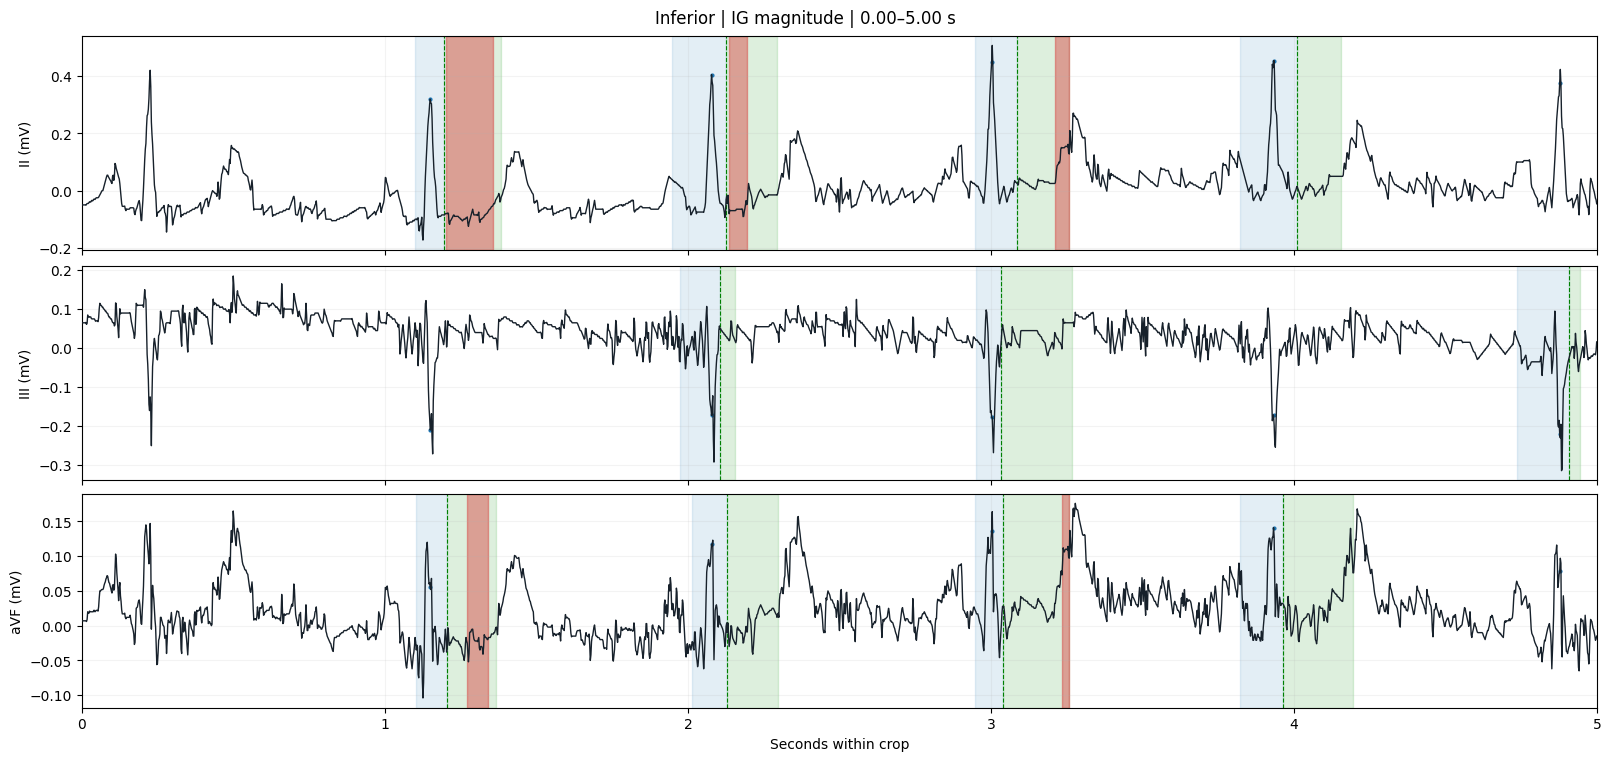

Blue: candidate QRS/R; green: candidate ST; red: attribution constrained to ST


In [82]:
def runs(mask):
    edges = np.diff(np.r_[False, mask, False].astype(int))
    return list(zip(np.flatnonzero(edges == 1), np.flatnonzero(edges == -1)))

def focused_st_regions(values, candidates, fs=FS, percentile=75, smooth_ms=8,
                       min_ms=20, gap_ms=8, max_regions_per_lead=3):
    values = np.asarray(values, dtype=float)
    if values.shape != (12,N) or not np.isfinite(values).all(): raise ValueError('Expected finite [12,N] attribution')
    if not 0 <= percentile <= 100: raise ValueError('Invalid percentile')
    if max_regions_per_lead <= 0: return []
    prepared = []
    for c in candidates:
        i, a, b = LEADS.index(c['lead']), int(c['start']), int(c['end'])
        if not 0 <= a < b <= N: raise ValueError('Candidate outside crop')
        v = np.maximum(values[i,a:b], 0)
        if smooth_ms > 0: v = gaussian_filter1d(v, max(.1,fs*smooth_ms/1000), mode='nearest')
        prepared.append((c,v))
    positive = [v[v > 0] for _,v in prepared if np.any(v > 0)]
    if not positive: return []
    threshold = max(np.percentile(np.concatenate(positive), percentile), np.finfo(float).tiny)
    output = []
    for c,v in prepared:
        mask = (v >= threshold) & (v > 0)
        components = runs(mask)
        for (_,left_end),(right_start,_) in zip(components,components[1:]):
            if right_start-left_end <= round(gap_ms*fs/1000): mask[left_end:right_start] = True
        eligible = [(a,b) for a,b in runs(mask) if b-a >= max(1,round(min_ms*fs/1000))]
        if not eligible: continue
        a,b = max(eligible, key=lambda ab: float(v[ab[0]:ab[1]].sum()))
        output.append(dict(lead=c['lead'], beat=c['beat'], start=c['start']+a,
                           end=c['start']+b, score=float(v[a:b].sum())))
    kept = []
    for lead in LEADS:
        kept.extend(sorted([r for r in output if r['lead']==lead], key=lambda r:r['score'], reverse=True)[:max_regions_per_lead])
    return sorted(kept, key=lambda r:(LEADS.index(r['lead']), r['start']))

def attribution_values(method):
    if method.startswith('IG'):
        if ig_attr is None: return None
        a = ig_attr.detach().cpu().numpy()[0]
        return np.abs(a) if method == 'IG magnitude' else np.maximum(a if method == 'IG positive' else -a, 0)
    if method == 'DeepLift magnitude':
        return None if dl_attr is None else np.abs(dl_attr.detach().cpu().numpy()[0])
    if method == 'Grad-CAM (shared)':
        return None if cam_result is None else np.repeat(cam_result['raw'].cpu().numpy(), 12, axis=0)
    raise ValueError('Unknown attribution method')

def focus_bounds(values, ids, window, mode, focus_start=0.):
    width = min(N, max(2, round(window*FS)))
    if mode == 'Manual' or values is None:
        a = int(np.clip(round(focus_start*FS), 0, N-width)); return a,a+width
    evidence = values[ids].sum(axis=0)
    if mode == 'Highest ST attribution':
        mask = np.zeros((12,N), bool)
        for c in st_candidates: mask[LEADS.index(c['lead']), c['start']:c['end']] = True
        evidence = (values[ids]*mask[ids]).sum(axis=0)
    scores = np.convolve(evidence, np.ones(width), mode='valid')
    a = int(np.argmax(scores)) if np.any(scores > 0) else 0
    return a,a+width

def clinical_xai_viewer(group='Inferior', window=1.2, method='IG magnitude',
                        mode='Highest ST attribution', focus_start=0., percentile=75,
                        show_qrs=True, show_st=True, show_ig=True, full_heatmap=False):
    ids = [LEADS.index(name) for name in GROUPS[group]]
    values = attribution_values(method)
    a,b = focus_bounds(values, ids, window, mode, focus_start)
    selected = focused_st_regions(values, st_candidates, percentile=percentile) if values is not None else []
    fig, axes = plt.subplots(len(ids),1,figsize=(16,max(3,2.5*len(ids))),sharex=True, squeeze=False,
                             constrained_layout=True)
    scale = max(float(np.percentile(values,99.5)),1e-12) if values is not None else 1.
    for ax,i in zip(axes.ravel(),ids):
        ax.plot(time[a:b],display_ecg[i,a:b],color='#17212B',lw=1.,zorder=5)
        if show_ig and full_heatmap and values is not None:
            lo,hi = ax.get_ylim()
            ax.imshow(values[i,a:b][None], extent=(a/FS,b/FS,lo,hi), aspect='auto',
                      cmap='Reds',norm=Normalize(0,scale),alpha=.4,origin='lower',zorder=0)
        for c in st_candidates:
            if c['lead'] != LEADS[i]: continue
            if show_qrs and 'qrs_on' in c:
                l,r = max(a,c['qrs_on']),min(b,c['start'])
                if l<r: ax.axvspan(l/FS,r/FS,color='tab:blue',alpha=.12)
            if show_st:
                l,r = max(a,c['start']),min(b,c['end'])
                if l<r: ax.axvspan(l/FS,r/FS,color='tab:green',alpha=.16)
                if a <= c['start'] < b: ax.axvline(c['start']/FS,color='green',ls='--',lw=.8)
        if show_ig and not full_heatmap:
            for r in selected:
                if r['lead'] == LEADS[i] and max(a,r['start']) < min(b,r['end']):
                    ax.axvspan(max(a,r['start'])/FS,min(b,r['end'])/FS,color='tab:red',alpha=.4)
        for r in rpeaks:
            if a<=r<b: ax.plot(r/FS,display_ecg[i,r],'.',color='tab:blue',ms=4)
        ax.set_ylabel(LEADS[i]+' (mV)'); ax.grid(alpha=.15); ax.set_xlim(a/FS,b/FS)
    axes[-1,0].set_xlabel('Seconds within crop')
    fig.suptitle(f'{group} | {method} | {a/FS:.2f}–{b/FS:.2f} s')
    if show_ig and full_heatmap and values is not None:
        fig.colorbar(ScalarMappable(norm=Normalize(0,scale),cmap='Reds'),ax=list(axes.ravel()),label='Attribution (shared scale)')
    plt.show()
    print('Blue: candidate QRS/R; green: candidate ST; red: '+('full attribution' if full_heatmap else 'attribution constrained to ST'))
    if values is None: print('Selected attribution unavailable; showing ECG and landmarks only.')
    if not st_candidates: print('No accepted ST intervals: inspect rejection table or use reviewed manual intervals.')
    if method.startswith('Grad-CAM'): print('Shared temporal CAM across leads; coarse layer resolution, interpolated for display.')
    return fig

# Static overview remains usable without widgets.
clinical_xai_viewer(window=DURATION_SECONDS, mode='Manual');

In [83]:
# Original dashboard/focus use cases are available through mode and full_heatmap controls.
show_ecg_dashboard = clinical_xai_viewer
focus_ecg = clinical_xai_viewer
view_clinical_xai = clinical_xai_viewer
try:
    import ipywidgets as widgets
    controls = dict(
        group=widgets.Dropdown(options=list(GROUPS), value='Inferior'),
        window=widgets.FloatSlider(value=1.2,min=.4,max=DURATION_SECONDS,step=.1),
        method=widgets.Dropdown(options=['IG magnitude','IG positive','IG negative','Grad-CAM (shared)','DeepLift magnitude']),
        mode=widgets.Dropdown(options=['Highest ST attribution','Highest attribution','Manual']),
        focus_start=widgets.FloatSlider(value=0,min=0,max=max(0,DURATION_SECONDS-.4),step=.1),
        percentile=widgets.IntSlider(value=75,min=50,max=99),
        show_qrs=widgets.Checkbox(value=True), show_st=widgets.Checkbox(value=True),
        show_ig=widgets.Checkbox(value=True), full_heatmap=widgets.Checkbox(value=False))
    display(widgets.VBox(list(controls.values())),widgets.interactive_output(clinical_xai_viewer, controls))
except ImportError:
    print('ipywidgets unavailable: call clinical_xai_viewer(...) directly.')

Output()

gradCam

In [84]:
print("Grad-CAM class:", "TemporalGradCAM" in globals())
print("CAM result exists:", "cam_result" in globals())

if "cam_result" in globals():
    print("CAM result type:", type(cam_result))
    print("CAM result:", str(cam_result)[:500])

Grad-CAM class: True
CAM result exists: True
CAM result type: <class 'dict'>
CAM result: {'raw': tensor([[0., 0., 0.,  ..., 0., 0., 0.]], device='cuda:0'), 'normalized': tensor([[0., 0., 0.,  ..., 0., 0., 0.]], device='cuda:0'), 'coarse_signed': tensor([[-5.2569e-05, -5.4735e-05, -7.8948e-05, -1.4201e-04, -1.5789e-04,
         -1.0346e-04, -7.4100e-05,  7.2023e-05, -1.1798e-04, -7.8218e-05,
         -1.1305e-04, -1.2059e-04, -6.3711e-05, -7.4588e-05, -1.0160e-04,
         -8.5038e-05, -7.9036e-05, -1.5468e-04, -1.0787e-04, -1.0816e-04,
         -1.0962e-04, -6.6830e-05, -9.8151e-05,


In [85]:
import torch

for key in ["raw", "normalized", "coarse_signed"]:
    x = cam_result[key].detach().float()

    print(f"\n{key}")
    print("Shape:", tuple(x.shape))
    print("Min:", x.min().item())
    print("Max:", x.max().item())
    print("Mean:", x.mean().item())
    print("Nonzero:", torch.count_nonzero(x).item())
    print("Finite:", torch.isfinite(x).all().item())


raw
Shape: (1, 2500)
Min: 0.0
Max: 7.064048259053379e-05
Mean: 1.3475741980073508e-06
Nonzero: 128
Finite: True

normalized
Shape: (1, 2500)
Min: 0.0
Max: 1.0
Mean: 0.0190765131264925
Nonzero: 128
Finite: True

coarse_signed
Shape: (1, 156)
Min: -0.0002869660675060004
Max: 7.202332199085504e-05
Mean: -0.00010336264676880091
Nonzero: 156
Finite: True


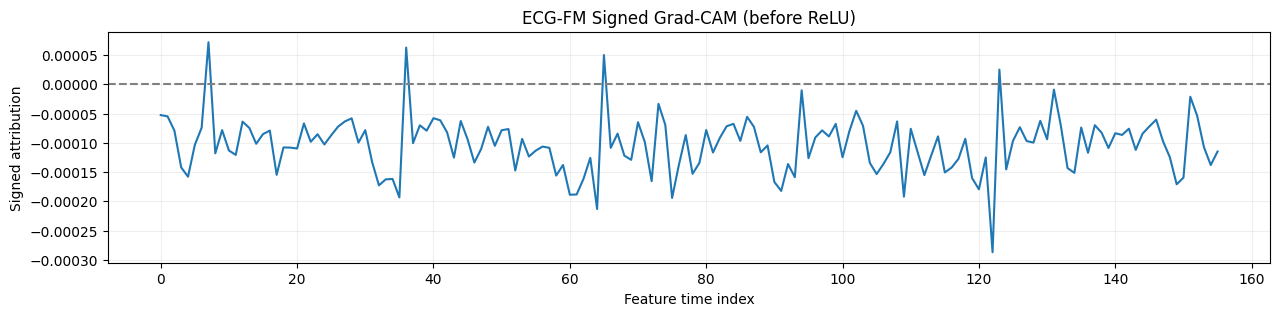

In [86]:
import matplotlib.pyplot as plt

cam = cam_result["coarse_signed"][0].detach().cpu().numpy()

plt.figure(figsize=(15, 3))
plt.plot(cam)
plt.axhline(0, color="gray", linestyle="--")
plt.title("ECG-FM Signed Grad-CAM (before ReLU)")
plt.xlabel("Feature time index")
plt.ylabel("Signed attribution")
plt.grid(alpha=0.2)
plt.show()

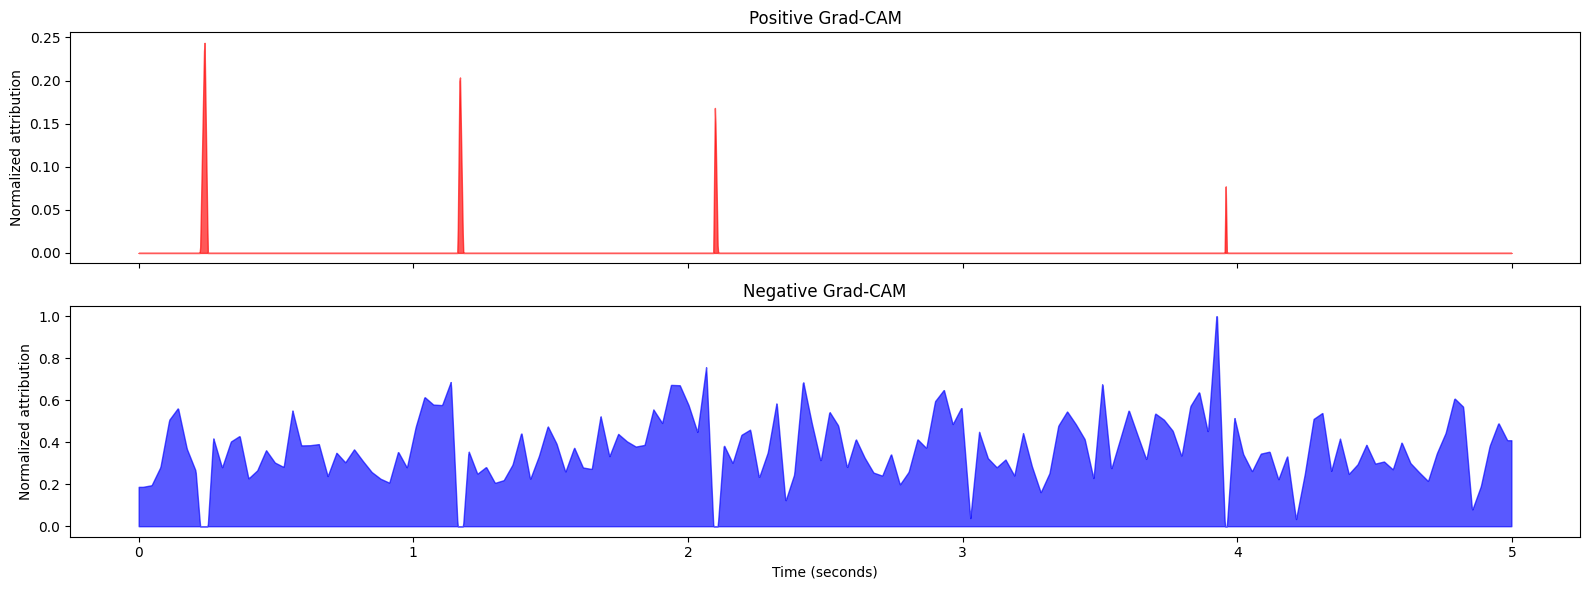

In [87]:
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

signed = cam_result["coarse_signed"].detach().float()

# Upsample to original ECG length
signed = F.interpolate(
    signed.unsqueeze(1),
    size=ecg_tensor.shape[-1],
    mode="linear",
    align_corners=False
).squeeze(1)[0].cpu().numpy()

scale = np.max(np.abs(signed)) + 1e-12
signed = signed / scale

positive = np.clip(signed, 0, None)
negative = np.clip(-signed, 0, None)

time = np.arange(len(signed)) / 500

fig, axes = plt.subplots(2, 1, figsize=(16, 6), sharex=True)

axes[0].fill_between(
    time, positive,
    color="red", alpha=0.65
)
axes[0].set_title("Positive Grad-CAM")
axes[0].set_ylabel("Normalized attribution")

axes[1].fill_between(
    time, negative,
    color="blue", alpha=0.65
)
axes[1].set_title("Negative Grad-CAM")
axes[1].set_ylabel("Normalized attribution")
axes[1].set_xlabel("Time (seconds)")

plt.tight_layout()
plt.show()

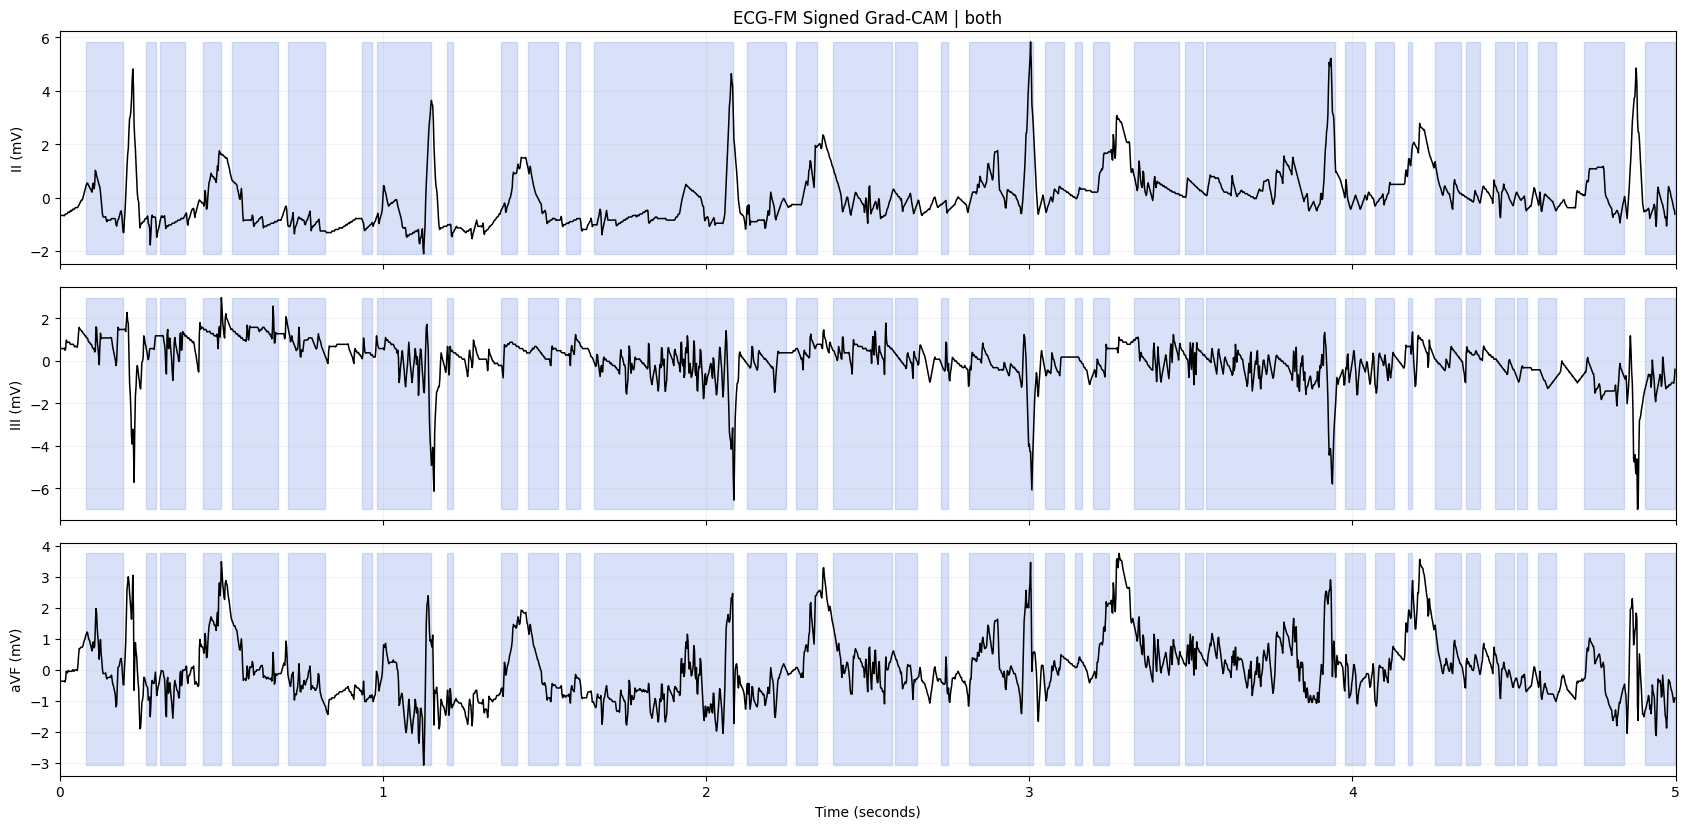

In [88]:
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

FS = 500
LEADS = [
    "I", "II", "III", "aVR", "aVL", "aVF",
    "V1", "V2", "V3", "V4", "V5", "V6"
]

def to_numpy(x):
    if isinstance(x, torch.Tensor):
        return x.detach().float().cpu().numpy()
    return np.asarray(x)

# Signed Grad-CAM: [1, 156] -> [1, 2500]
signed_cam = cam_result["coarse_signed"].detach().float()

signed_cam = F.interpolate(
    signed_cam.unsqueeze(1),
    size=ecg_tensor.shape[-1],
    mode="linear",
    align_corners=False
).squeeze(1)[0]

signed_cam = to_numpy(signed_cam)

# Normalize to [-1, 1]
signed_cam = signed_cam / (
    np.max(np.abs(signed_cam)) + 1e-12
)

ecg = to_numpy(ecg_tensor)[0]
time = np.arange(ecg.shape[-1]) / FS

def plot_gradcam_ecg(
    leads=("II", "III", "aVF"),
    mode="both",
    threshold=0.3,
    start=0,
    end=5,
):
    fig, axes = plt.subplots(
        len(leads), 1,
        figsize=(17, 2.8 * len(leads)),
        sharex=True
    )

    axes = np.atleast_1d(axes)

    for ax, lead in zip(axes, leads):
        idx = LEADS.index(lead)

        ax.plot(
            time, ecg[idx],
            color="black",
            linewidth=1.1,
            zorder=3
        )

        pos = np.clip(signed_cam, 0, None)
        neg = np.clip(-signed_cam, 0, None)

        if mode in ("positive", "both"):
            ax.fill_between(
                time,
                ecg[idx].min(),
                ecg[idx].max(),
                where=pos >= threshold,
                color="red",
                alpha=0.28,
                zorder=1
            )

        if mode in ("negative", "both"):
            ax.fill_between(
                time,
                ecg[idx].min(),
                ecg[idx].max(),
                where=neg >= threshold,
                color="royalblue",
                alpha=0.20,
                zorder=1
            )

        ax.set_ylabel(f"{lead} (mV)")
        ax.set_xlim(start, end)
        ax.grid(alpha=0.15)

    axes[0].set_title(
        f"ECG-FM Signed Grad-CAM | {mode}"
    )
    axes[-1].set_xlabel("Time (seconds)")
    plt.tight_layout()
    plt.show()

plot_gradcam_ecg(
    leads=("II", "III", "aVF"),
    mode="both",
    threshold=0.3
)

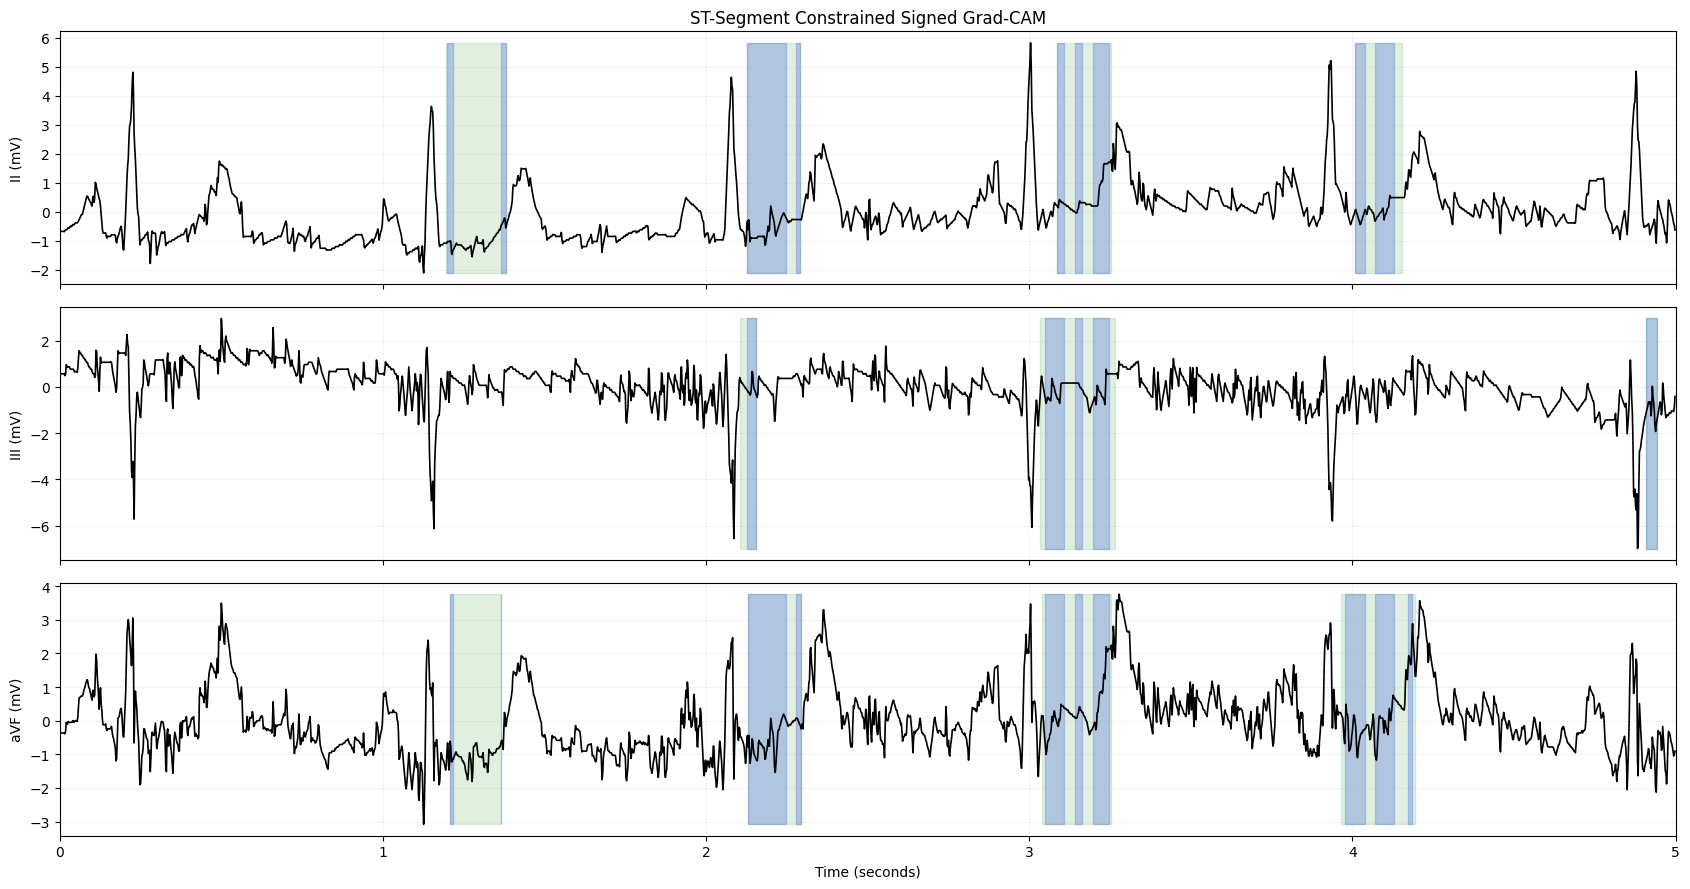

In [89]:
import pandas as pd

def build_st_mask(
    st_candidates,
    lead,
    n_samples
):
    mask = np.zeros(n_samples, dtype=bool)

    if isinstance(st_candidates, pd.DataFrame):
        records = st_candidates.to_dict("records")
    else:
        records = list(st_candidates)

    for item in records:
        if not isinstance(item, dict):
            continue

        candidate_lead = item.get(
            "lead", item.get("lead_name")
        )

        if candidate_lead != lead:
            continue

        start = item.get(
            "start", item.get("start_idx")
        )
        end = item.get(
            "end", item.get("end_idx")
        )

        if start is None or end is None:
            continue

        a = max(0, int(start))
        b = min(n_samples, int(end))

        if b > a:
            mask[a:b] = True

    return mask


def plot_st_gradcam(
    leads=("II", "III", "aVF"),
    threshold=0.3,
    start=0,
    end=5
):
    if "st_candidates" not in globals():
        raise NameError(
            "st_candidates not found. "
            "Run the NeuroKit2 delineation cell first."
        )

    fig, axes = plt.subplots(
        len(leads), 1,
        figsize=(17, 3 * len(leads)),
        sharex=True
    )
    axes = np.atleast_1d(axes)

    for ax, lead in zip(axes, leads):
        idx = LEADS.index(lead)

        st_mask = build_st_mask(
            st_candidates,
            lead,
            len(time)
        )

        positive = np.clip(signed_cam, 0, None)
        negative = np.clip(-signed_cam, 0, None)

        ax.plot(
            time, ecg[idx],
            color="black",
            linewidth=1.2,
            zorder=3
        )

        ax.fill_between(
            time,
            ecg[idx].min(),
            ecg[idx].max(),
            where=st_mask,
            color="green",
            alpha=0.12
        )

        ax.fill_between(
            time,
            ecg[idx].min(),
            ecg[idx].max(),
            where=st_mask & (positive >= threshold),
            color="red",
            alpha=0.45
        )

        ax.fill_between(
            time,
            ecg[idx].min(),
            ecg[idx].max(),
            where=st_mask & (negative >= threshold),
            color="royalblue",
            alpha=0.30
        )

        ax.set_ylabel(f"{lead} (mV)")
        ax.set_xlim(start, end)
        ax.grid(alpha=0.15)

    axes[0].set_title(
        "ST-Segment Constrained Signed Grad-CAM"
    )
    axes[-1].set_xlabel("Time (seconds)")

    plt.tight_layout()
    plt.show()


plot_st_gradcam(
    leads=("II", "III", "aVF"),
    threshold=0.3
)

In [90]:
import ipywidgets as widgets
from IPython.display import display

lead_selector = widgets.SelectMultiple(
    options=LEADS,
    value=("II", "III", "aVF"),
    description="Leads"
)

mode_selector = widgets.Dropdown(
    options=["both", "positive", "negative"],
    value="both",
    description="CAM mode"
)

threshold_slider = widgets.FloatSlider(
    value=0.3,
    min=0.05,
    max=0.95,
    step=0.05,
    description="Threshold"
)

st_only = widgets.Checkbox(
    value=False,
    description="ST segment only"
)

def update_view(
    leads,
    mode,
    threshold,
    st_only
):
    if not leads:
        print("Select at least one lead")
        return

    if st_only:
        plot_st_gradcam(
            leads=leads,
            threshold=threshold
        )
    else:
        plot_gradcam_ecg(
            leads=leads,
            mode=mode,
            threshold=threshold
        )

widgets.interact(
    update_view,
    leads=lead_selector,
    mode=mode_selector,
    threshold=threshold_slider,
    st_only=st_only
)

interactive(children=(SelectMultiple(description='Leads', index=(1, 2, 5), options=('I', 'II', 'III', 'aVR', '…

<function __main__.update_view(leads, mode, threshold, st_only)>

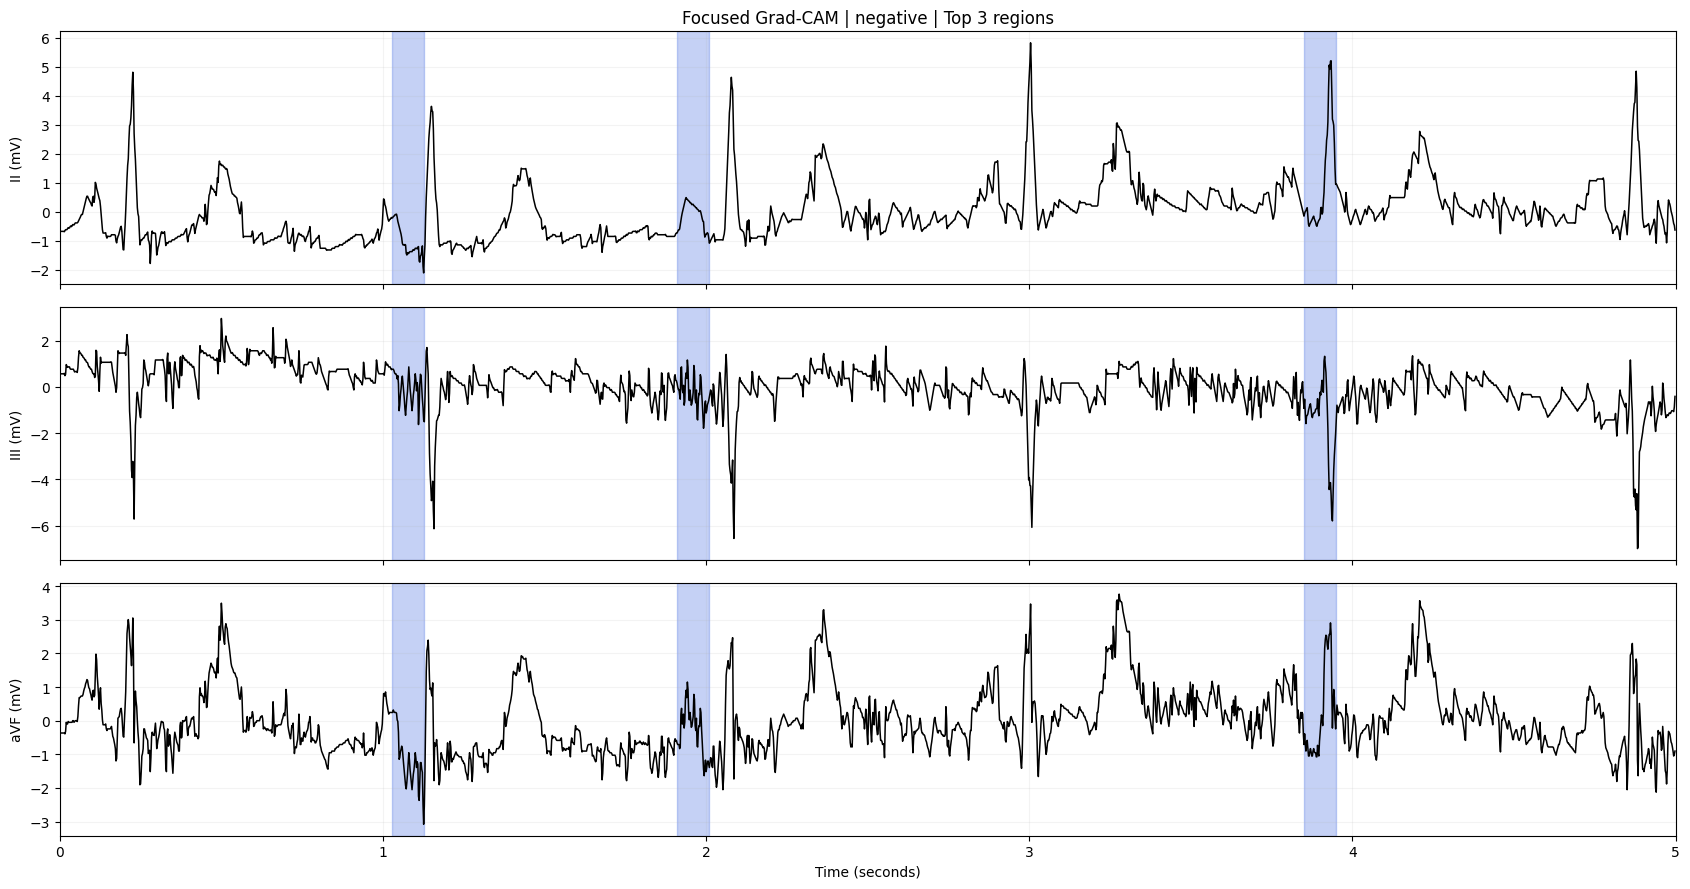

In [91]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d

def focused_gradcam(
    leads=("II", "III", "aVF"),
    mode="negative",
    top_k=3,
    min_distance_ms=150,
    smooth_ms=30,
    region_ms=100,
    start=0,
    end=5
):
    fs = FS
    n = len(signed_cam)

    cam = np.asarray(signed_cam, dtype=float)

    if mode == "positive":
        scores = np.maximum(cam, 0)
    elif mode == "negative":
        scores = np.maximum(-cam, 0)
    else:
        scores = np.abs(cam)

    scores = gaussian_filter1d(
        scores,
        sigma=max(1, smooth_ms * fs / 1000)
    )

    from scipy.signal import find_peaks

    peaks, _ = find_peaks(
        scores,
        distance=max(1, int(min_distance_ms * fs / 1000))
    )

    peaks = sorted(
        peaks,
        key=lambda p: scores[p],
        reverse=True
    )[:top_k]

    peaks = sorted(peaks)

    fig, axes = plt.subplots(
        len(leads), 1,
        figsize=(17, 3 * len(leads)),
        sharex=True
    )
    axes = np.atleast_1d(axes)

    for ax, lead in zip(axes, leads):
        idx = LEADS.index(lead)

        ax.plot(
            time,
            ecg[idx],
            color="black",
            linewidth=1.1
        )

        for peak in peaks:
            center = peak / fs
            half_width = region_ms / 2000

            ax.axvspan(
                center - half_width,
                center + half_width,
                color="royalblue" if mode == "negative" else "red",
                alpha=0.3
            )

        ax.set_ylabel(f"{lead} (mV)")
        ax.set_xlim(start, end)
        ax.grid(alpha=0.15)

    axes[0].set_title(
        f"Focused Grad-CAM | {mode} | Top {top_k} regions"
    )
    axes[-1].set_xlabel("Time (seconds)")

    plt.tight_layout()
    plt.show()


focused_gradcam(
    leads=("II", "III", "aVF"),
    mode="negative",
    top_k=3,
    region_ms=100
)

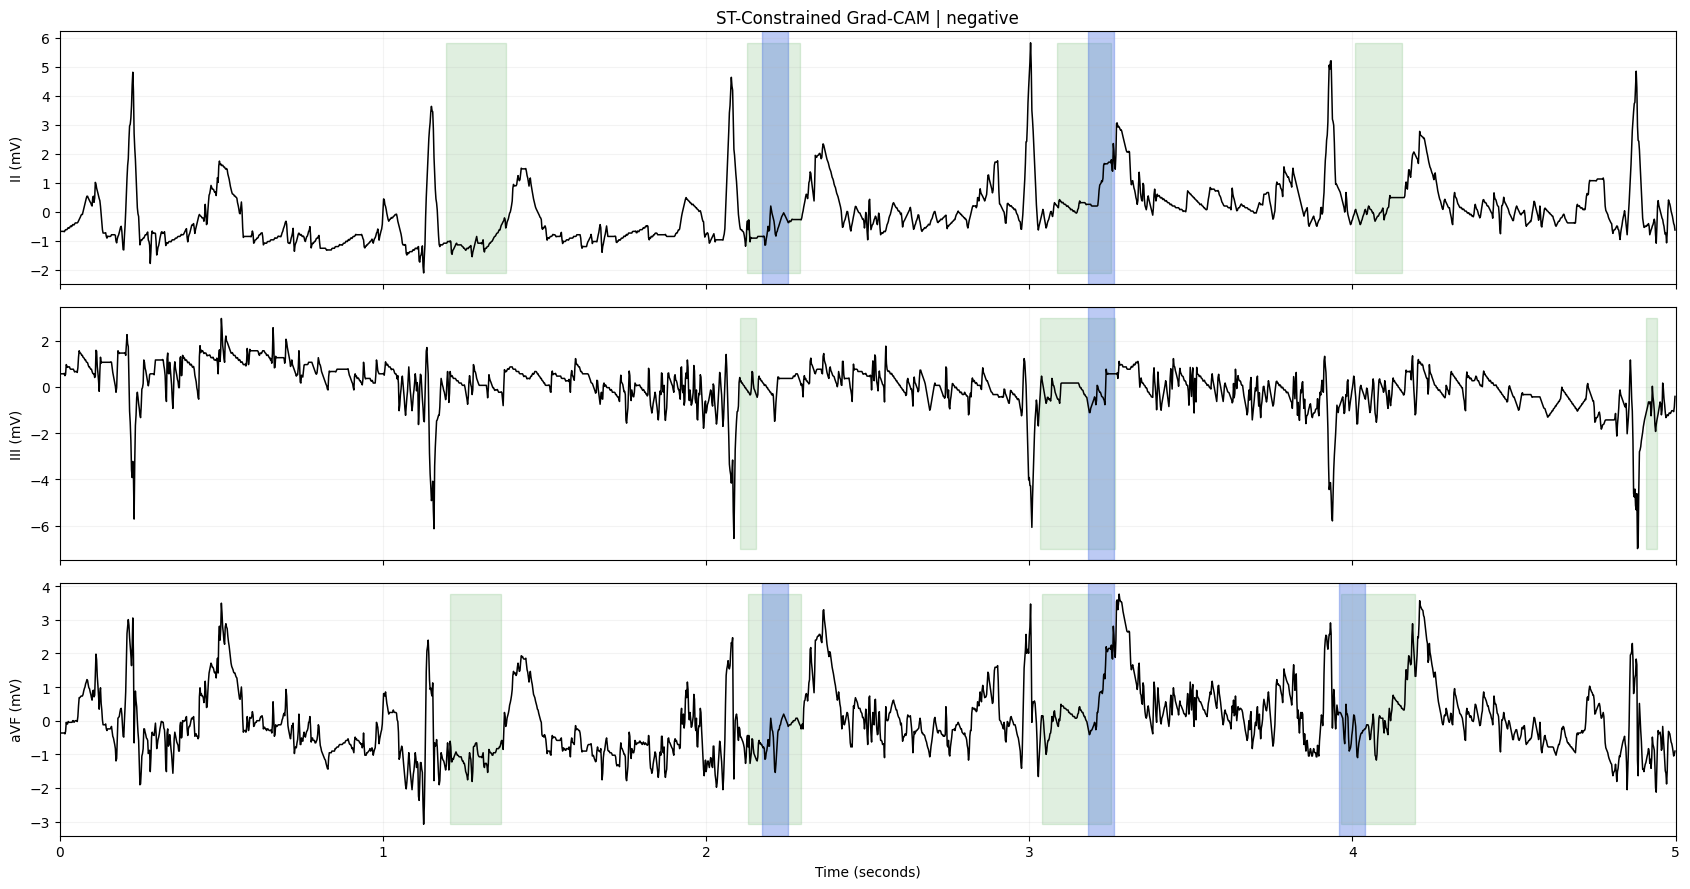

In [93]:
def focused_st_gradcam(
    leads=("II", "III", "aVF"),
    mode="negative",
    top_k=3,
    threshold=0.3,
    start=0,
    end=5
):
    if "st_candidates" not in globals():
        raise RuntimeError("Run NeuroKit2 ST delineation first")

    cam = np.asarray(signed_cam)

    if mode == "positive":
        scores = np.maximum(cam, 0)
    elif mode == "negative":
        scores = np.maximum(-cam, 0)
    else:
        scores = np.abs(cam)

    # Shared temporal Grad-CAM
    st_union = np.zeros(len(cam), dtype=bool)

    for lead in leads:
        st_union |= build_st_mask(
            st_candidates, lead, len(cam)
        )

    # Rank only samples inside ST candidates
    masked_scores = np.where(st_union, scores, 0)

    from scipy.ndimage import gaussian_filter1d
    from scipy.signal import find_peaks

    smoothed = gaussian_filter1d(
        masked_scores, sigma=5
    )

    peaks, _ = find_peaks(
        smoothed,
        distance=int(0.15 * FS),
        height=threshold
    )

    peaks = sorted(
        peaks,
        key=lambda p: smoothed[p],
        reverse=True
    )[:top_k]

    fig, axes = plt.subplots(
        len(leads), 1,
        figsize=(17, 3 * len(leads)),
        sharex=True
    )
    axes = np.atleast_1d(axes)

    for ax, lead in zip(axes, leads):
        idx = LEADS.index(lead)
        lead_st = build_st_mask(
            st_candidates, lead, len(cam)
        )

        ax.plot(time, ecg[idx], color="black", lw=1.1)

        ax.fill_between(
            time,
            ecg[idx].min(),
            ecg[idx].max(),
            where=lead_st,
            color="green",
            alpha=0.12
        )

        for peak in peaks:
            if not lead_st[peak]:
                continue

            center = peak / FS
            ax.axvspan(
                center - 0.04,
                center + 0.04,
                color="royalblue",
                alpha=0.35
            )

        ax.set_ylabel(f"{lead} (mV)")
        ax.set_xlim(start, end)
        ax.grid(alpha=0.15)

    axes[0].set_title(
        f"ST-Constrained Grad-CAM | {mode}"
    )
    axes[-1].set_xlabel("Time (seconds)")

    plt.tight_layout()
    plt.show()


focused_st_gradcam(
    leads=("II", "III", "aVF"),
    mode="negative",
    top_k=3,
    threshold=0.3
)

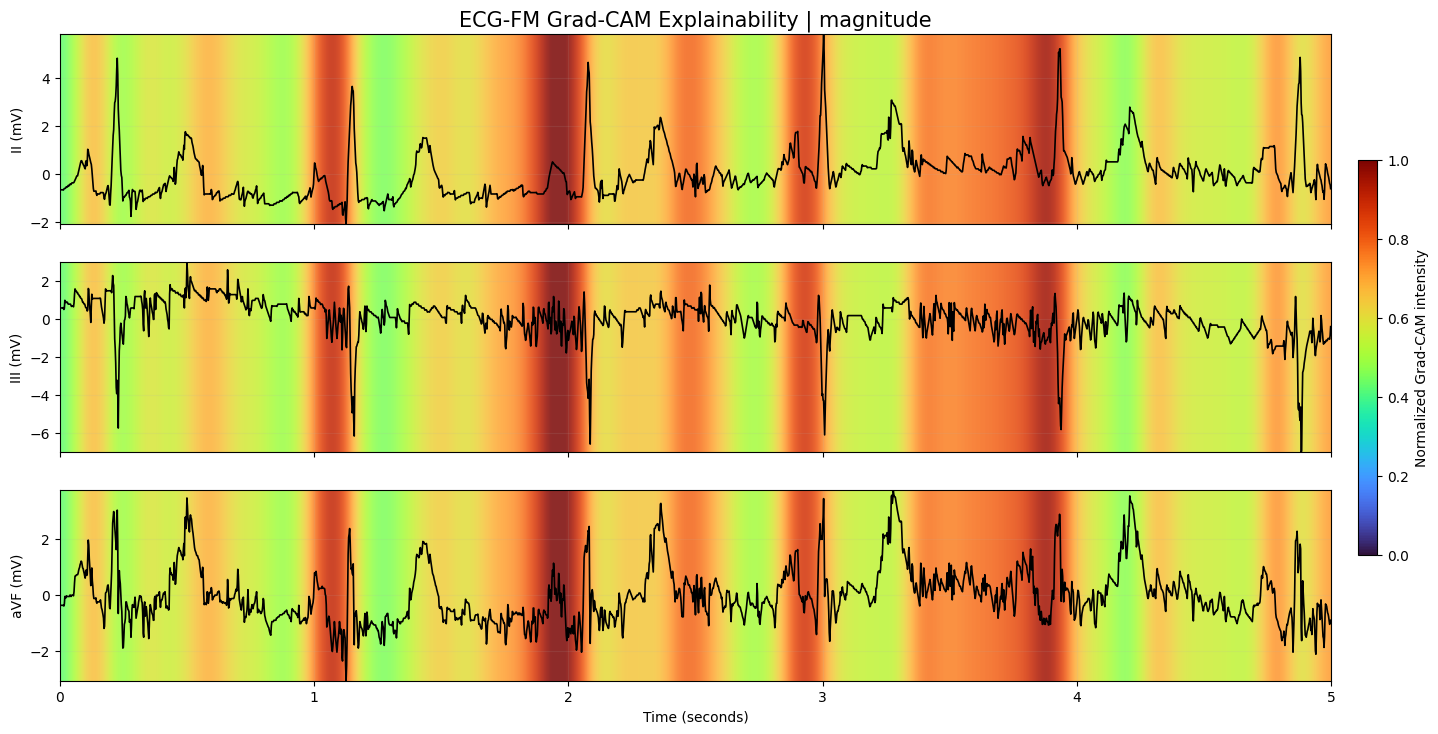

In [94]:
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from scipy.ndimage import gaussian_filter1d

def plot_gradcam_heatmap(
    leads=("II", "III", "aVF"),
    mode="magnitude",
    smooth_ms=60,
    start=0,
    end=5,
    cmap="turbo",
    intensity=0.85,
):
    fs = FS

    # Original ECG
    signal = ecg_tensor.detach().float().cpu().numpy()[0]
    n_samples = signal.shape[-1]
    t = np.arange(n_samples) / fs

    # Original signed Grad-CAM
    cam = cam_result["coarse_signed"].detach().float()

    # Upsample CAM to ECG resolution
    cam = F.interpolate(
        cam.unsqueeze(1),
        size=n_samples,
        mode="linear",
        align_corners=False
    ).squeeze(1)[0].cpu().numpy()

    # Select attribution mode
    if mode == "positive":
        cam = np.maximum(cam, 0)
    elif mode == "negative":
        cam = np.maximum(-cam, 0)
    elif mode == "magnitude":
        cam = np.abs(cam)
    else:
        raise ValueError("Invalid mode")

    # Smooth heatmap
    sigma = max(0, smooth_ms * fs / 1000)
    if sigma > 0:
        cam = gaussian_filter1d(cam, sigma=sigma)

    # Robust normalization
    scale = np.percentile(cam, 99)

    if scale > 0:
        cam = np.clip(cam / scale, 0, 1)
    else:
        cam = np.zeros_like(cam)

    fig, axes = plt.subplots(
        len(leads), 1,
        figsize=(17, 2.8 * len(leads)),
        sharex=True
    )

    axes = np.atleast_1d(axes)

    for ax, lead in zip(axes, leads):
        idx = LEADS.index(lead)
        y = signal[idx]

        # Create continuous heatmap
        heatmap = np.tile(cam, (100, 1))

        ax.imshow(
            heatmap,
            extent=[t[0], t[-1] + 1/fs, y.min(), y.max()],
            origin="lower",
            aspect="auto",
            cmap=cmap,
            vmin=0,
            vmax=1,
            alpha=intensity,
            interpolation="bilinear",
            zorder=0
        )

        # ECG waveform on top
        ax.plot(
            t, y,
            color="black",
            linewidth=1.2,
            zorder=3
        )

        ax.set_ylabel(f"{lead} (mV)")
        ax.set_xlim(start, end)
        ax.grid(alpha=0.12)

    axes[0].set_title(
        f"ECG-FM Grad-CAM Explainability | {mode}",
        fontsize=15
    )

    axes[-1].set_xlabel("Time (seconds)")

    sm = plt.cm.ScalarMappable(
        cmap=cmap,
        norm=Normalize(vmin=0, vmax=1)
    )
    sm.set_array([])

    fig.colorbar(
        sm,
        ax=axes.tolist(),
        label="Normalized Grad-CAM intensity",
        fraction=0.015,
        pad=0.02
    )

    plt.show()


plot_gradcam_heatmap(
    leads=("II", "III", "aVF"),
    mode="magnitude",
    smooth_ms=60,
    cmap="turbo",
    intensity=0.85
)

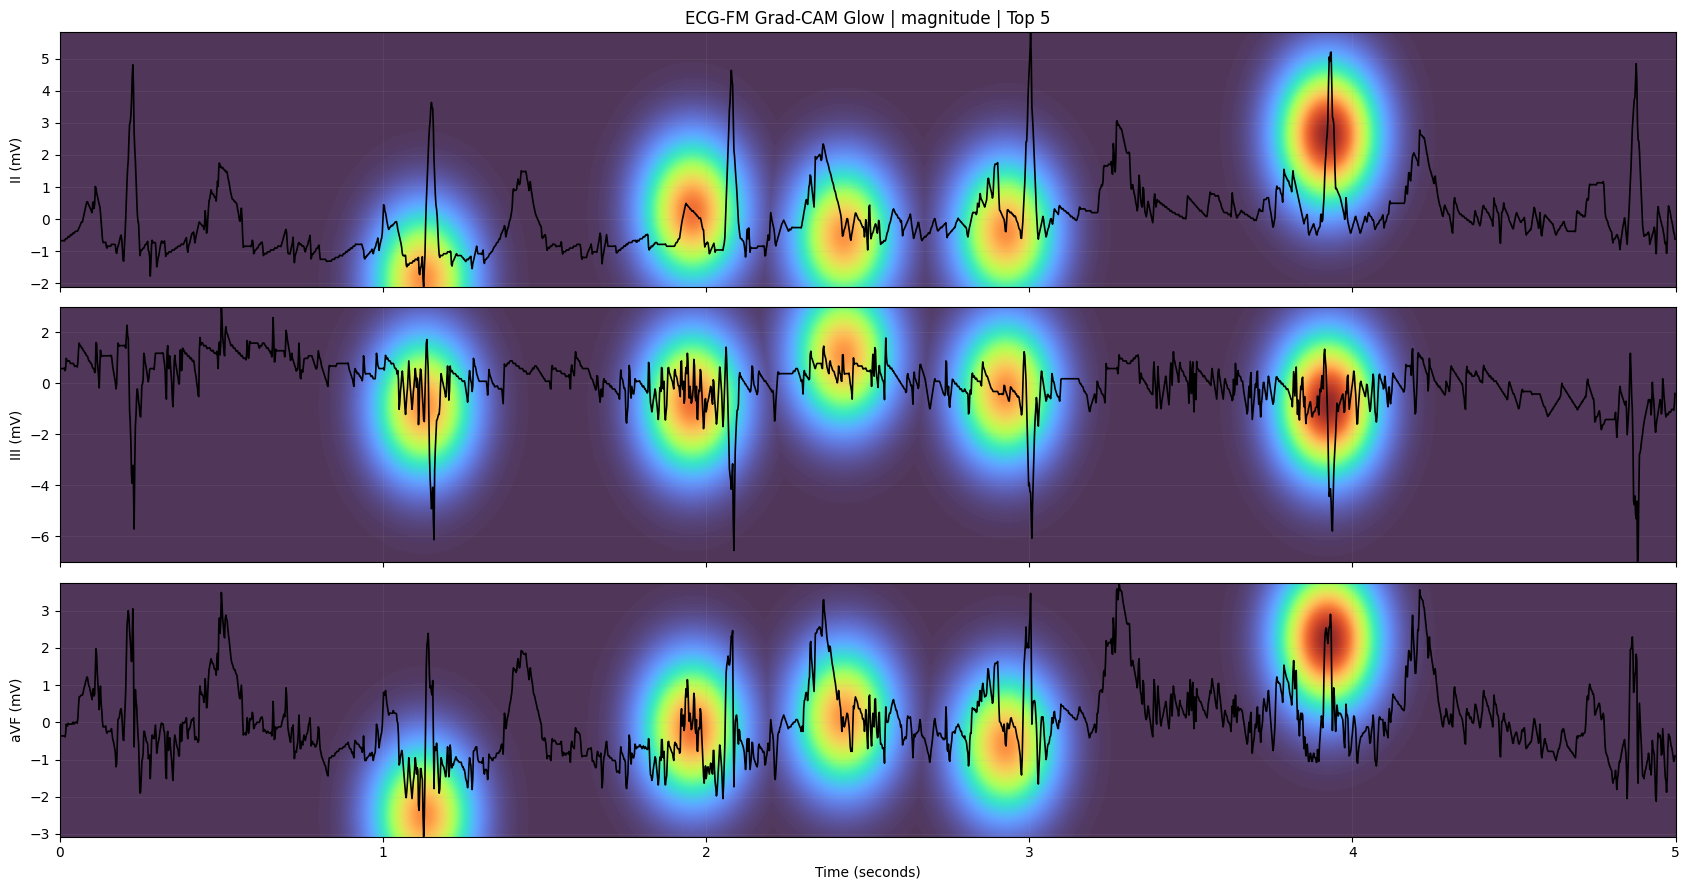

In [95]:
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks

def plot_gradcam_glow(
    leads=("II", "III", "aVF"),
    mode="magnitude",
    top_k=5,
    radius_ms=100,
    vertical_radius=0.18,
    min_distance_ms=200,
    start=0,
    end=5,
    cmap="turbo",
):
    signal = ecg_tensor.detach().float().cpu().numpy()[0]
    fs = FS
    n = signal.shape[-1]
    t = np.arange(n) / fs

    # Grad-CAM
    signed = cam_result["coarse_signed"].detach().float()

    cam = F.interpolate(
        signed.unsqueeze(1),
        size=n,
        mode="linear",
        align_corners=False
    ).squeeze(1)[0].cpu().numpy()

    if mode == "positive":
        scores = np.maximum(cam, 0)
    elif mode == "negative":
        scores = np.maximum(-cam, 0)
    elif mode == "magnitude":
        scores = np.abs(cam)
    else:
        raise ValueError("Invalid mode")

    scores = gaussian_filter1d(scores, sigma=5)

    maximum = scores.max()
    if maximum <= 0:
        print("No attribution available")
        return

    scores = scores / maximum

    # Find strongest attribution peaks
    peaks, _ = find_peaks(
        scores,
        distance=max(1, int(min_distance_ms * fs / 1000))
    )

    peaks = sorted(
        peaks,
        key=lambda p: scores[p],
        reverse=True
    )[:top_k]

    peaks = sorted(peaks)

    fig, axes = plt.subplots(
        len(leads), 1,
        figsize=(17, 3 * len(leads)),
        sharex=True
    )
    axes = np.atleast_1d(axes)

    for ax, lead in zip(axes, leads):
        idx = LEADS.index(lead)
        y = signal[idx]

        ymin, ymax = y.min(), y.max()
        yrange = ymax - ymin

        # 2D heatmap grid
        yy = np.linspace(ymin, ymax, 220)
        X, Y = np.meshgrid(t, yy)

        heatmap = np.zeros_like(X)

        for peak in peaks:
            center_t = t[peak]
            center_y = y[peak]

            sigma_t = radius_ms / 1000
            sigma_y = max(vertical_radius * yrange, 1e-8)

            blob = np.exp(
                -0.5 * (
                    ((X - center_t) / sigma_t) ** 2
                    +
                    ((Y - center_y) / sigma_y) ** 2
                )
            )

            heatmap = np.maximum(
                heatmap,
                blob * scores[peak]
            )

        ax.imshow(
            heatmap,
            extent=[t[0], t[-1] + 1/fs, ymin, ymax],
            origin="lower",
            aspect="auto",
            cmap=cmap,
            vmin=0,
            vmax=1,
            alpha=0.85,
            interpolation="bilinear",
            zorder=0
        )

        ax.plot(
            t, y,
            color="black",
            linewidth=1.2,
            zorder=3
        )

        ax.set_ylabel(f"{lead} (mV)")
        ax.set_xlim(start, end)
        ax.grid(alpha=0.1)

    axes[0].set_title(
        f"ECG-FM Grad-CAM Glow | {mode} | Top {top_k}"
    )
    axes[-1].set_xlabel("Time (seconds)")

    plt.tight_layout()
    plt.show()


plot_gradcam_glow(
    leads=("II", "III", "aVF"),
    mode="magnitude",
    top_k=5,
    radius_ms=100,
    vertical_radius=0.18
)